![](../../assets/header-logo.png)

## Simulation-Based Performance Study of Semantic Image Segmentation under Domain Shifts

**Automated and Connected Driving Challenges - Research Project - *04/2026***

**Research Topic *Topic 14: Simulation-Based Performance Study of Semantic Image Segmentation under Domain Shifts***



| Author | Mail |
| --- | --- |
| *Lufei Wang* | *lufei.wang@rwth-aachen.de* |
| *Yehor Buriachenko* | *yehor.buriachenko@rwth-aachen.de* |


#### Dependencies & Setup

##### Execution Environment

The offline sections run in the ACDC RP Jupyter container, the ROS 2 section in the project's ROS 2 Jazzy container. On an NVIDIA A40, the offline sections take about 15 minutes on first execution and 1–2 minutes once the evaluation results sit in their cache files; the training cells skip training while a checkpoint exists.

##### Downloads

The notebook reads `data/` (~18 GB) and four `checkpoints*/` directories (~835 MB), too large for Git; [README.md](README.md) explains how to link them on the RWTH filesystem or regenerate them.

##### Dependencies

The cell below installs the offline pipeline's Python dependencies via pip, with pinned versions for reproducibility. The project Docker image provides ROS 2 (`rclpy`, `sensor_msgs`, `cv_bridge`), so this cell does not install it.

In [10]:
# === INSTALLATION OF PYTHON DEPENDENCIES ==========================
# Pinned versions for reproducibility. Only missing or mismatched packages are
# installed; restart the kernel afterwards, because pip cannot safely replace a
# package this kernel has already imported (numpy, for example).
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version
try:
    from packaging.specifiers import SpecifierSet
except ImportError:
    from pip._vendor.packaging.specifiers import SpecifierSet

REQUIREMENTS = [
    "numpy~=1.26.4",
    "opencv-python~=4.8.0.76",
    "torch~=2.1.0",
    "torchvision~=0.16.0",
    "albumentations~=1.3.1",
    "matplotlib~=3.7.2",
    "mcap-ros2-support~=0.5.0",
    "tqdm~=4.66.1",
]

def is_installed(requirement):
    name, spec = requirement.split("~=")
    try:
        return version(name) in SpecifierSet("~=" + spec)
    except PackageNotFoundError:
        return False

missing = [r for r in REQUIREMENTS if not is_installed(r)]
if missing:
    print("Installing:", ", ".join(missing))
    result = subprocess.run([sys.executable, "-m", "pip", "install", *missing],
                            capture_output=True, text=True)
    print(result.stdout[-3000:] + result.stderr[-3000:])
    result.check_returncode()
    print("Done. Restart the kernel now (Kernel > Restart), then continue with the next cell.")
else:
    print("All pinned dependencies are already installed.")

# === INSTALLATION OF OTHER SYSTEM DEPENDENCIES ====================
# ROS 2 (rclpy, sensor_msgs, cv_bridge) is pre-installed in the
# project Docker environment and does not need to be installed here.

All pinned dependencies are already installed.


In [11]:
#IMPORTS 

import sys
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

# local modules (same directory as this notebook)
sys.path.insert(0, str(Path('.').resolve()))
from carla_labels import (
    REDUCED_CLASSES,
    CLASS_COLORS,
    RAW_TO_REDUCED,
    remap_label_image,
    label_to_color_image,
)
from data_extraction import extract_mcap
from dataset import SegmentationDataset, build_dataloaders
from model import LightUNet

# Abstract

Semantic segmentation models lose accuracy when the deployment environment differs from their training data. Rain, low light, an unfamiliar town, or a camera mounted at a different height can each break a model that scored well on its own distribution. This report measures how much each shift costs.

We generate every dataset in CARLAB, a web platform built on the CARLA simulator that produces exact pixel-level ground-truth labels. We train on ClearNoon data from three maps and evaluate on sixteen domains in five blocks: an in-distribution control, weather and lighting, map geometry, camera configuration, and a combined map-plus-weather block. The single-shift blocks vary one factor at a time, which attributes each accuracy drop to its cause; the combined block tests whether those costs add up.

We train LightUNet, a compact U-Net-style network, in PyTorch on the baseline data alone, then score it on every evaluation domain. We report mean Intersection-over-Union and per-class IoU and rank the shifts by how much they degrade accuracy. We implement two ROS 2 nodes for live operation in simulation: one performs inference on the sensor stream, the other synchronises predictions with simulation ground truth and computes frame-level, cumulative and per-class IoU metrics.

In-distribution mIoU reaches 0.68 to 0.75. Nighttime causes the largest single drop, to 0.23, followed by camera pitch (0.34) and mounting height (0.48); unseen towns cost the least (0.64 to 0.68), and combined map-plus-weather shifts behave near-additively. Targeted augmentation recovers part of both worst losses, night to 0.39 and camera pitch to 0.48, and each augmentation arm buys robustness on its axis at a small cost on the other. We conclude that synthetic data alone supports this kind of robustness study. We release the notebook, the CARLAB sensor configurations, the trained model, and the ROS 2 nodes in the project repository.

# Introduction

Perception drives automated and connected vehicles. Semantic image segmentation handles one part of it: the model assigns a class label to every pixel, so the vehicle reads its surroundings down to individual road markings, curbs, and pedestrians. Path planning, obstacle avoidance, and high-level decisions all depend on getting those labels right. A model trained on one environment often fails in another. This failure mode is called domain shift.

Domain shift has many sources on the road: weather, time of day, road type, and how each vehicle mounts and aims its camera. Each is a safety risk, and covering all of them with real labelled footage is too costly for a robustness study. Simulation is cheaper and more controllable: CARLA and the ika-hosted CARLAB platform produce exact pixel-level labels, and setting the simulation parameters creates one specific shift while everything else stays constant.

This work measures domain shift on a semantic segmentation model under controlled conditions: we train under ClearNoon on three maps and evaluate on sixteen domains in five blocks, where each single-factor block isolates the contribution of one shift. Two ROS 2 nodes run the model live on the simulated sensor stream and monitor frame-level and cumulative mIoU and per-class IoU.

This work contributes:

- a set of controlled CARLAB datasets that cover weather and lighting, map geometry, and camera configuration shifts relevant to automated driving;

- a trained LightUNet model and a per-shift breakdown of how much accuracy each shift removes;

- two ROS 2 nodes for live inference and online evaluation, a practical setup for monitoring perception reliability in simulation;

- a reproducible Jupyter notebook with all code, CARLAB configurations, the trained model, and the evaluation results.


# Related Work

Simulation lets researchers generate driving data with exact labels and full control over the environment. CARLA [[1]](#ref1) provides the open-source simulator that most of this work builds on, including ours through the CARLAB platform. Synthetic ground truth for segmentation predates it: SYNTHIA [[13]](#ref13) rendered a purpose-built virtual city, and Richter et al. [[14]](#ref14) harvested pixel-accurate labels from a commercial game, together establishing that synthetic pixels can train real segmentation models. Several datasets push synthetic data further toward domain-shift research. SELMA [[2]](#ref2) collects multimodal acquisitions across weather, daytime, and viewpoints. SHIFT [[3]](#ref3) is the closest prior work to ours: Sun et al. build a large CARLA dataset of 2.5M annotated frames across eight locations that varies cloudiness, rain, fog, time of day, vehicle and pedestrian density, and camera orientation, then measure how perception accuracy falls as each shift grows. They train on a clear-daytime source domain and evaluate on the shifted domains, the control-variable protocol we adopt. Our study applies the same paradigm at a smaller scale: one lightweight network, about 4,700 training frames, eight classes, and sixteen evaluation domains we generate in CARLAB. We trade SHIFT's breadth for tight single-factor control and a reproducible end-to-end notebook. On the real-data side, ACDC [[15]](#ref15) collects fog, night, rain, and snow scenes aligned with clear-weather references of the same locations; it is the real-world benchmark for the adverse-condition degradation we measure in simulation.

Semantic segmentation architectures set the accuracy ceiling for this task. Fully convolutional networks [[4]](#ref4) established dense per-pixel prediction. SegNet [[8]](#ref8) established the efficient encoder-decoder design for segmentation, pairing each encoder stage with a decoder stage that upsamples using the encoder pooling indices, while U-Net [[10]](#ref10) introduced the skip concatenations between matching encoder and decoder stages that LightUNet follows directly. DeepLabv3+ [[5]](#ref5) added atrous separable convolutions for multi-scale context, and SegFormer [[6]](#ref6) replaced the convolutional backbone with a transformer. We choose a small U-Net-style network over these heavier models, since our goal is measuring shift rather than maximizing accuracy, and the model must run in real time inside the ROS 2 node. One further property of convolutional networks matters for our camera block: despite their nominal translation invariance, CNNs encode absolute image position through zero-padding boundary effects [[11]](#ref11), which predicts viewpoint sensitivity of the kind our Block D results show. Cityscapes [[7]](#ref7) remains the reference real-world segmentation benchmark, and we follow its class taxonomy and void-handling convention so our metric matches common practice.

# Methodology

We study domain shift on semantic segmentation through a four-stage pipeline: generate the data, build the data pipeline and model, train and evaluate, then run the model live in ROS 2.

## 1. Synthetic Dataset Generation using CARLAB

We generate every dataset with CARLAB [[12]](#ref12), which runs on the open-source CARLA simulator [[1]](#ref1) and lets us record an RGB camera alongside a segmentation pseudo-sensor that outputs per-pixel ground-truth labels. We pair it with a control-variable design that isolates one domain shift at a time.

### 1.1 ROS 2 Topics Recorded

Only the four topics required for segmentation training and evaluation are recorded. We exclude LiDAR (`PointCloud2`), odometry, TF, vehicle status, and other non-visual topics to save storage.

| Topic | Message Type | Purpose |
|-------|-------------|---------|
| `/carla/ego_vehicle/rgb/image/compressed` | `sensor_msgs/CompressedImage` | Model input |
| `/carla/ego_vehicle/segmentation/image/compressed` | `sensor_msgs/CompressedImage` | Ground-truth semantic label |
| `/carla/ego_vehicle/rgb/camera_info` | `sensor_msgs/CameraInfo` | Camera intrinsics |
| `/carla/weather` | `carla_msgs/CarlaWeatherParameters` | Active weather metadata |

We study three types of domain shift:

| Shift Type | Training Value | Variants Tested |
|------------|---------------|-----------------|
| Weather & lighting | ClearNoon | WetNoon, HardRainNoon, ClearSunset, ClearNight |
| Map geometry | Town10HD_Opt, Town01, Town05 | Town02, Town03, Town04 (all unseen) |
| Camera configuration | z=3.0m, pitch=20°, FOV=90° (chase view) | z=1.5m / pitch=35° / FOV=110° |

### 1.2 Training dataset

We train the model on data collected under **ClearNoon** weather across three maps with distinct road layouts. No adverse weather, nighttime conditions, or alternative camera configurations appear in the training set.

Because the model never sees those conditions, any accuracy it keeps under a shift comes from generalisation.

| ID | Town | Description | Extracted frames |
|----|------|-------------|-----------------|
| T1 | Town10HD_Opt | Dense city centre, various road types and landmarks, features a tree-lined boulevard | 1,842 |
| T2 | Town01 | Small town with T-junctions, residential and commercial mix, with a river and several bridges | 1,839 |
| T3 | Town05 | Square grid map with a raised highway and large multilane roads and junctions. | 1,845 |

<br>

<table border="0" style="border-collapse: collapse; border: none; width: 100%; text-align: center;">
  <tr style="border: none;">
    <td style="border: none; padding: 10px; width: 33.33%; vertical-align: top;">
      <img src="paper_images/town10.jpg" style="width: 100%; height: 220px; object-fit: cover; border-radius: 4px;"><br>
      <strong style="font-size: 0.9em; color: #555;">T1 — Town10HD_Opt</strong>
    </td>
    <td style="border: none; padding: 10px; width: 33.33%; vertical-align: top;">
      <img src="paper_images/town01.jpg" style="width: 100%; height: 220px; object-fit: cover; border-radius: 4px;"><br>
      <strong style="font-size: 0.9em; color: #555;">T2 — Town01</strong>
    </td>
    <td style="border: none; padding: 10px; width: 33.33%; vertical-align: top;">
      <img src="paper_images/town05.jpg" style="width: 100%; height: 220px; object-fit: cover; border-radius: 4px;"><br>
      <strong style="font-size: 0.9em; color: #555;">T3 — Town05</strong>
    </td>
  </tr>
</table>

<br>

**Total training data: 5,526 frames after extraction.** We reserve a contiguous time-tail of each town as a held-out split for checkpoint selection (829 frames), leaving 4,697 frames for training. The domain blocks in section 1.3 serve only as the evaluation test set.

### 1.3 Evaluation Domains

We group sixteen evaluation domains into five blocks. Each block isolates a specific type of domain shift. All runs share the training traffic configuration (15 vehicles at 0.4 occupancy, 10 pedestrians) and last 10 simulated minutes.

### Block A: In-Distribution Sanity Check (3 domains)

Same maps and weather as training, different spawn point. Establishes the **expected upper bound** on model performance. Poor performance here would point to a training or implementation error.

| ID | Town | Weather | Camera | Role |
|----|------|---------|--------|------|
| V1 | Town10HD | ClearNoon | Standard | Baseline upper bound |
| V2 | Town01 | ClearNoon | Standard | Baseline upper bound |
| V3 | Town05 | ClearNoon | Standard | Baseline upper bound |

### Block B: Weather and Lighting Shift (4 domains)

Map fixed at Town10HD (training map). Weather and time of day vary. Isolates the effect of **visual appearance shifts**. We measure each domain against V1.

| ID | Weather | Domain Shift |
|----|----|----|
| V4 | WetNoon | Mild: wet surfaces, reflections |
| V5 | HardRainNoon | Severe: rain streaks, reduced contrast |
| V6 | ClearSunset | Moderate: low-angle light, long shadows |
| V7 | ClearNight | Severe: near-total loss of ambient light |


### Block C: Map Geometry Shift (3 domains)

Weather fixed at ClearNoon. Unseen maps only. Isolates the effect of **unfamiliar road structures and scene compositions**.

| ID | Town | Description | Domain Shift |
|----|----|----|----|
| V8 | Town02 | Small town with numerous T-junctions and a variety of residential and commercial buildings | Near-OOD (similar scale to Town01) |
| V9 | Town03 | Larger town with features of a downtown urban area such as a roundabout, underpasses and overpasses. | Moderate OOD: unique structures |
| V10 | Town04 | Small network of short streets and junctions, with a "figure of 8" style ringroad, an underpass/overpass and circular slip roads | Strong OOD: high-speed highway geometry |

<br>

<table border="0" style="border-collapse: collapse; border: none; width: 100%; text-align: center;">
  <tr style="border: none;">
    <td style="border: none; padding: 10px; width: 33.33%; vertical-align: top;">
      <img src="paper_images/town02.jpg" style="width: 100%; height: 220px; object-fit: cover; border-radius: 4px;"><br>
      <strong style="font-size: 0.9em; color: #555;">V8 — Town02</strong>
    </td>
    <td style="border: none; padding: 10px; width: 33.33%; vertical-align: top;">
      <img src="paper_images/town03.jpg" style="width: 100%; height: 220px; object-fit: cover; border-radius: 4px;"><br>
      <strong style="font-size: 0.9em; color: #555;">V9 — Town03</strong>
    </td>
    <td style="border: none; padding: 10px; width: 33.33%; vertical-align: top;">
      <img src="paper_images/town04_1.jpg" style="width: 100%; height: 220px; object-fit: cover; border-radius: 4px;"><br>
      <strong style="font-size: 0.9em; color: #555;">V10 — Town04</strong>
    </td>
  </tr>
</table>

<br>

### Block D: Camera and Sensor Configuration Shift (3 domains)

Map and weather fixed at Town10HD + ClearNoon (identical to V1). Only the camera parameters change. Tests sensitivity to the **viewpoint and field-of-view assumptions** the model absorbs during training.

| ID | Camera Change | Parameter Changed | Domain Shift |
|----|----|----|----|
| V11 | Lower mounting height | z = 1.5 m (vs. 3.0 m) | Different road/sky proportion |
| V12 | Downward pitch | pitch = 35° (vs. 20°) | More road, less sky visible |
| V13 | Wider field of view | FOV = 110° (vs. 90°) | Smaller apparent object scale, stretching at frame edges |

**Standard camera parameters** (used in all other runs):  
Position: x=−6.0 m, y=0.0 m, z=3.0 m | Rotation: pitch=20°, yaw=0°, roll=0° | FOV=90° | Resolution: 1024×512

### Block E: Combined Shift (3 domains)

Each run combines an unseen map with adverse lighting or weather. These runs represent **realistic worst-case deployment scenarios** and provide a lower-bound estimate of robustness under compounded shift.

| ID | Town | Weather | Shifts Combined |
|----|----|----|----|
| V14 | Town03 | HardRainNoon | Unseen geometry + severe rain |
| V15 | Town04 | ClearNight | Unseen geometry + nighttime |
| V16 | Town02 | ClearSunset | Unseen map + low-angle light |




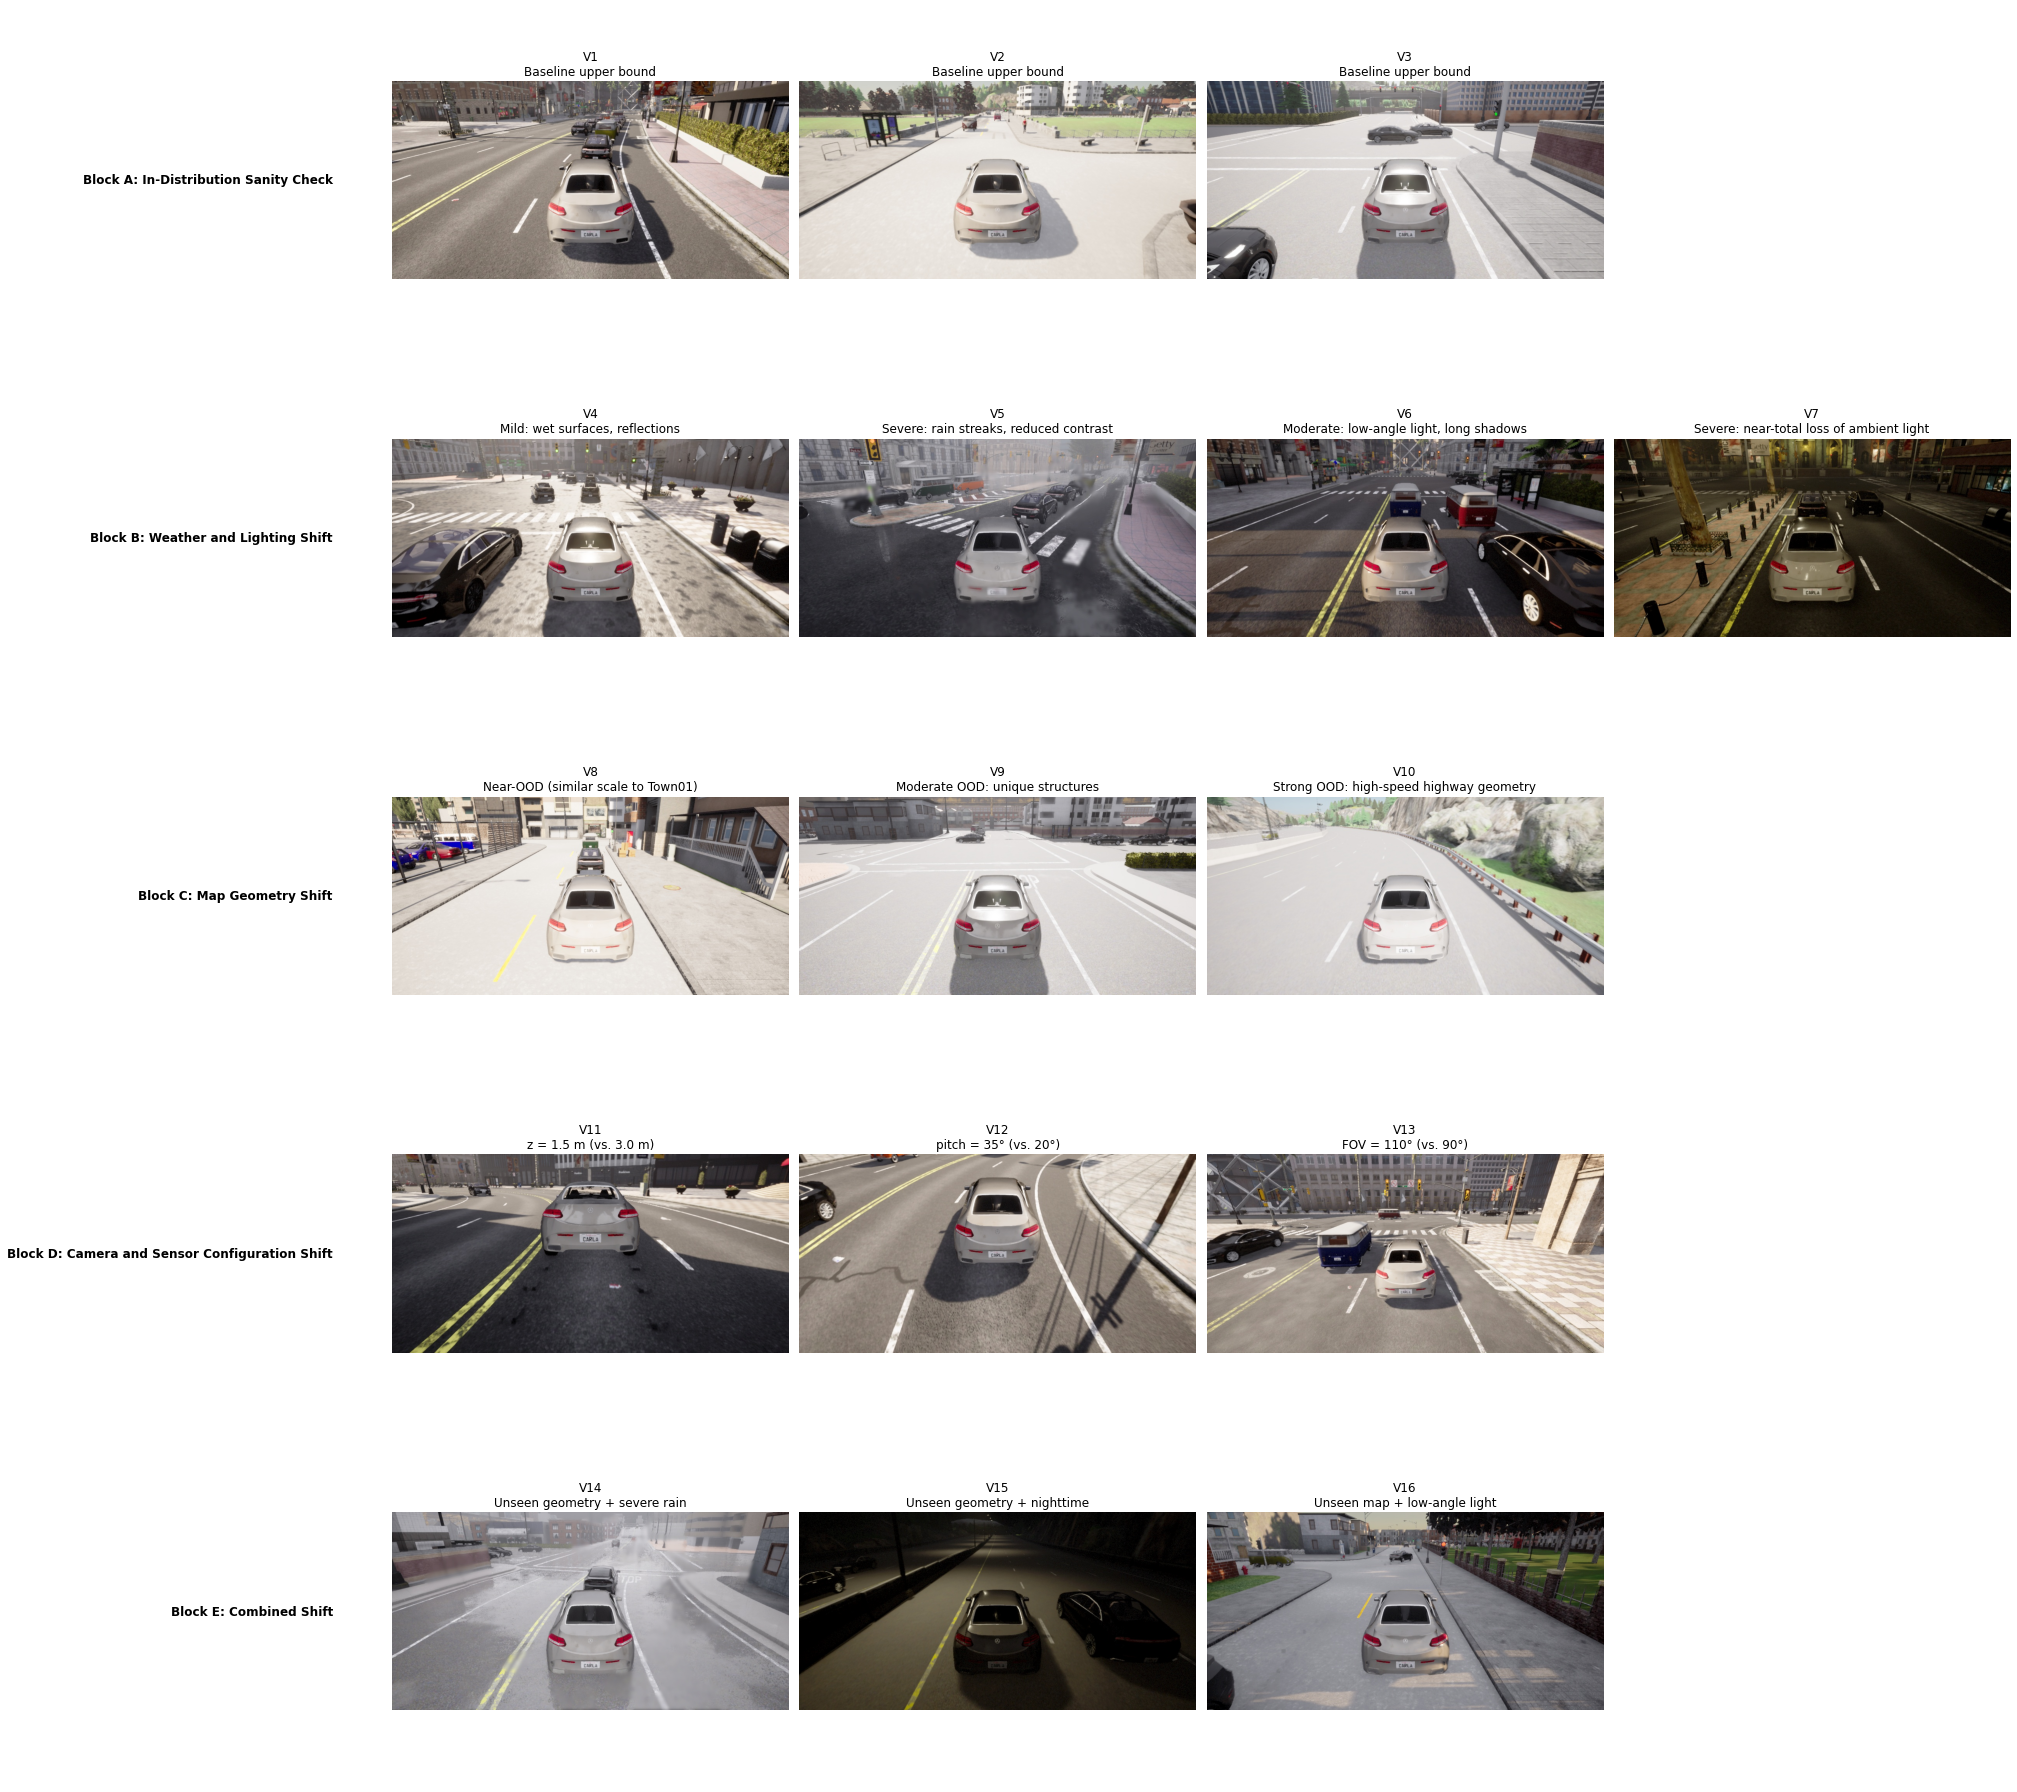

In [12]:
# One representative RGB frame from each of the sixteen evaluation
# domains (Section 1.3), grouped by block: one row per block.
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# (video ID, short location/weather tag, caption reused from the Section 1.3 tables)
EVAL_DOMAINS = {
    "A": [
        ("V1", "Town10HD_Opt, ClearNoon", "Baseline upper bound"),
        ("V2", "Town01, ClearNoon", "Baseline upper bound"),
        ("V3", "Town05, ClearNoon", "Baseline upper bound"),
    ],
    "B": [
        ("V4", "Town10HD_Opt, WetNoon", "Mild: wet surfaces, reflections"),
        ("V5", "Town10HD, HardRainNoon", "Severe: rain streaks, reduced contrast"),
        ("V6", "Town10HD_Opt, ClearSunset", "Moderate: low-angle light, long shadows"),
        ("V7", "Town10HD, ClearNight", "Severe: near-total loss of ambient light"),
    ],
    "C": [
        ("V8", "Town02, ClearNoon", "Near-OOD (similar scale to Town01)"),
        ("V9", "Town03, ClearNoon", "Moderate OOD: unique structures"),
        ("V10", "Town04, ClearNoon", "Strong OOD: high-speed highway geometry"),
    ],
    "D": [
        ("V11", "Town10HD_Opt, z=1.5m", "z = 1.5 m (vs. 3.0 m)"),
        ("V12", "Town10HD_Opt, pitch=35°", "pitch = 35° (vs. 20°)"),
        ("V13", "Town10HD_Opt, FOV=110°", "FOV = 110° (vs. 90°)"),
    ],
    "E": [
        ("V14", "Town03, HardRainNoon", "Unseen geometry + severe rain"),
        ("V15", "Town04, ClearNight", "Unseen geometry + nighttime"),
        ("V16", "Town02, ClearSunset", "Unseen map + low-angle light"),
    ],
}

BLOCK_TITLES = {
    "A": "In-Distribution Sanity Check",
    "B": "Weather and Lighting Shift",
    "C": "Map Geometry Shift",
    "D": "Camera and Sensor Configuration Shift",
    "E": "Combined Shift",
}

block_letters = list(EVAL_DOMAINS.keys())
n_rows = len(block_letters)
n_cols = max(len(entries) for entries in EVAL_DOMAINS.values())

fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 5 * n_rows))

for row, block in enumerate(block_letters):
    entries = EVAL_DOMAINS[block]
    for col in range(n_cols):
        ax = axes[row, col]
        ax.axis("off")
        if col >= len(entries):
            continue
        vid, desc, caption = entries[col]
        frames = sorted(Path(f"data/extracted/{vid}/images").glob("*.png"))
        if block == "B" and vid == "V4":
            rgb = cv2.cvtColor(cv2.imread(str(frames[50])), cv2.COLOR_BGR2RGB)
        else:
            rgb = cv2.cvtColor(cv2.imread(str(frames[len(frames) // 2])), cv2.COLOR_BGR2RGB)
        ax.imshow(rgb)
        ax.set_title(f"{vid}\n{caption}", fontsize=12)
    axes[row, 0].text(
        -0.15, 0.5, f"Block {block}: {BLOCK_TITLES[block]}",
        transform=axes[row, 0].transAxes, ha="right", va="center",
        fontsize=12, fontweight="bold",
    )

plt.tight_layout()
plt.show()


#### Label Schema

CARLA's semantic camera produces per-pixel class IDs from a set of **23 raw categories** (e.g. `Road`, `RoadLine`, `Fence`, `GuardRail`, `TrafficLight`). Many of these are rare, visually similar, or not safety-critical for the scope of this study. We therefore collapse them into **8 semantically meaningful classes** defined in `carla_labels.py`, and send CARLA's `Unlabeled` (void) pixels to a 255 ignore index that neither the loss nor the metric counts:

| ID | Class | Merged CARLA categories |
|---|---|---|
| 0 | road | Road, RoadLine |
| 1 | sidewalk | Sidewalk |
| 2 | building | Building, Wall, Bridge |
| 3 | vegetation | Vegetation, Terrain |
| 4 | vehicle | Vehicles |
| 5 | pedestrian | Pedestrian |
| 6 | sky | Sky |
| 7 | other | Fence, Pole, TrafficSign, TrafficLight, Static, Dynamic, Water, … |
| 255 | *ignore* | Unlabeled (CARLA void); excluded from loss and IoU |

**Grouping to eight classes.** A smaller label set lowers task difficulty and gives most classes enough pixels across domains for a stable per-class IoU. The grouping matches what a driving system acts on: the drivable surface (road), the obstacles (vehicles, pedestrians), and the surrounding structure (building, vegetation, sky). Frequencies stay skewed after grouping (pedestrian covers ~0.006% of pixels), which we counter with log-frequency loss weighting (see Training).

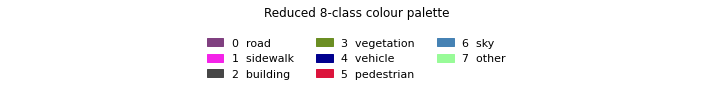

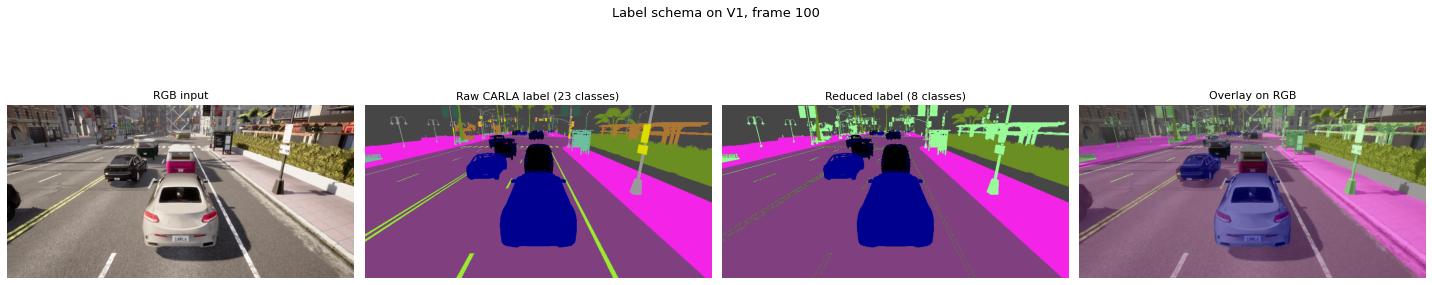

In [13]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2

sys.path.insert(0, str(Path('.').resolve()))
from carla_labels import (
    CARLA_CITYSCAPES_PALETTE, cityscapes_rgb_to_raw_ids,
    remap_label_image, label_to_color_image,
)

# Visualise the 8-class colour palette used for all label images
fig, ax = plt.subplots(figsize=(10, 1.5))
ax.axis('off')
patches = [
    mpatches.Patch(color=np.array(CLASS_COLORS[i]) / 255.0,
                   label=f"{i}  {REDUCED_CLASSES[i]}")
    for i in range(len(REDUCED_CLASSES))
]
ax.legend(handles=patches, loc='center', ncol=3, fontsize=11,
          frameon=False, handlelength=1.5)
ax.set_title("Reduced 8-class colour palette", fontsize=12, pad=8)
plt.tight_layout()
plt.show()

SAVED_FRAME = 100  # data/extracted/V1/images/000100.png
img_path = Path(f"data/extracted/V1/images/{SAVED_FRAME:06d}.png")
raw_label_path = Path("data/label_schema_sample/V1_000100_raw_cityscapes.png")

rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
label_rgb = cv2.cvtColor(cv2.imread(str(raw_label_path)), cv2.COLOR_BGR2RGB)

raw_ids = cityscapes_rgb_to_raw_ids(label_rgb)          # true 23-class IDs
reduced_ids = remap_label_image(raw_ids)                 # collapsed to 8 classes

raw_palette = np.zeros((256, 3), dtype=np.uint8)
for class_id, color in CARLA_CITYSCAPES_PALETTE.items():
    raw_palette[class_id] = color
raw_color = raw_palette[raw_ids]
reduced_color = label_to_color_image(reduced_ids)

overlay = cv2.addWeighted(rgb, 0.5, reduced_color, 0.5, 0)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img, title in zip(
    axes,
    [rgb, raw_color, reduced_color, overlay],
    ["RGB input", "Raw CARLA label (23 classes)", "Reduced label (8 classes)", "Overlay on RGB"],
):
    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.suptitle(f"Label schema on V1, frame {SAVED_FRAME}", fontsize=13)
plt.tight_layout()
plt.show()


## 2. Data Pipeline and Model Implementation

### Data Extraction

CARLAB saves simulation recordings as **MCAP files** (the ROS 2 bag format). Each recording contains timestamped messages on two topics relevant to this work:

- `/carla/ego_vehicle/rgb/image/compressed`: 8-bit RGB camera image
- `/carla/ego_vehicle/segmentation/image/compressed`: a Cityscapes-colourised semantic image (JPEG, per the `format` field of the recorded messages) where each colour encodes one of CARLA's 23 raw classes

`extract_mcap` in `data_extraction.py` reads both topics in one pass and pairs frames by arrival order: CARLA renders the RGB image and its semantic label in the same simulation tick, so the i-th message on one topic belongs to the i-th on the other. We pair by order instead of by timestamp because the ROS 2 bridge can delay the two topics against each other by more than 50 ms; the script prints the per-topic message counts of every recording, where a dropped frame would surface as a count mismatch. It decodes the colourised label back to raw CARLA IDs by nearest-colour matching against the Cityscapes palette. This matching absorbs the lossy JPEG compression of the label stream: pixels in a thin band along class boundaries can decode to a neighbouring class, an error that applies to every domain alike and leaves the domain comparisons intact. The function then remaps the raw IDs to the eight reduced classes with CARLA's void sent to 255 and writes each pair as lossless PNGs: the RGB frame in `images/`, the reduced labels in `labels/`.

In [14]:
# Training data was extracted from 3 MCAP recordings and merged via prepare_datasets.py.

from pathlib import Path

train_dir = Path("data/train")
val_dir = Path("data/val")
img_files   = sorted((train_dir / "images").glob("*.png"))
label_files = sorted((train_dir / "labels").glob("*.png"))
val_files = sorted((val_dir / "images").glob("*.png"))


assert len(img_files) > 0, "data/train is empty — run extraction + prepare_datasets.py first."
assert len(img_files) == len(label_files), \
    f"Count mismatch: {len(img_files)} images vs {len(label_files)} labels."

print(f"Training frames : {len(img_files)}")
print(f"Validation frames: {len(val_files)}")
print(f"  T1 (Town10) + T2 (Town01) + T3 (Town05) merged")
print(f"  Images dir  : {train_dir / 'images'}")
print(f"  Labels dir  : {train_dir / 'labels'}")

Training frames : 4697
Validation frames: 829
  T1 (Town10) + T2 (Town01) + T3 (Town05) merged
  Images dir  : data/train/images
  Labels dir  : data/train/labels


### Dataset and Transforms

`SegmentationDataset` (in `dataset.py`) loads the PNG pairs produced by the extraction step and wraps them in a PyTorch `Dataset` for use with `DataLoader`.

The table lists the transforms of each training variant and of the validation and test splits:

| Transform | Baseline | `photo` | `geo` | `full` | Val / Test |
|---|---|---|---|---|---|
| Resize to (256 × 512), INTER_AREA | ✓ | ✓ | ✓ | ✓ | ✓ |
| Horizontal flip (p=0.5) | — | ✓ | ✓ | ✓ | — |
| Colour jitter, strong (brightness 0.2–1.2×) | — | ✓ | — | ✓ | — |
| Gaussian noise | — | ✓ | — | ✓ | — |
| Shift-scale-rotate (y-shift ±15%, scale 0.65–1.5×, ±3°, 255-filled borders) | — | — | ✓ | ✓ | — |
| Normalise (ImageNet stats) | ✓ | ✓ | ✓ | ✓ | ✓ |

**Augmentation: off for the reported baseline, targeted variants as ablations.** The headline model trains on raw resized-and-normalised frames, so its numbers measure what the network learns from the data itself. The `augment` flag in `dataset.py` then selects one of three training-time variants. They target the shift families this study measures, while the model still never sees the real test domains: `photo` approximates low light by darkening noon frames, without street lights, headlights, or night sky; `geo` approximates mount changes by warping the view, without real parallax, and fills exposed borders with the 255 ignore value so they never enter the loss; `full` combines both arms.

The mechanism analysis in the Evaluation section predicts where each arm must act if its explanations hold: `photo` on Block B, with night sky IoU moving off 0.00; `geo` on Block D, with V12 building moving off 0.06 and gains ordered pitch, then height, then FOV.

**ImageNet normalisation.** We scale inputs with the standard ImageNet mean/std. We train LightUNet from scratch (no pretrained weights), so these statistics serve as conventional input scaling.

We store labels as `int64` tensors with values in `[0, 7]` plus the 255 ignore value.

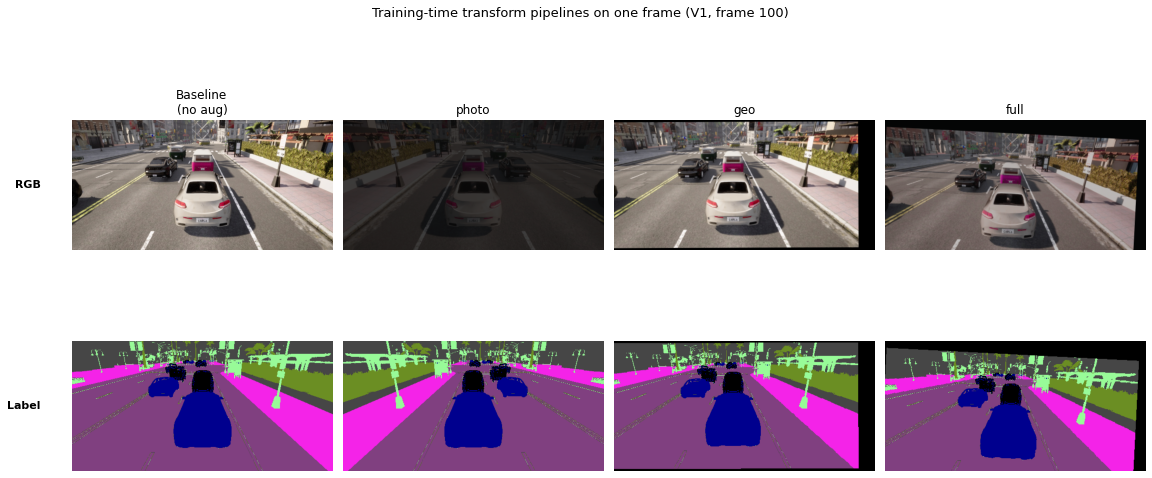

In [15]:
# Table above: baseline vs the photo / geo / full
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from dataset import get_transforms, MEAN, STD
from carla_labels import label_to_color_image

img_path = Path("data/extracted/V1/images/000100.png")
label_path = Path("data/extracted/V1/labels/000100.png")
rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
label = cv2.imread(str(label_path), cv2.IMREAD_GRAYSCALE)

VARIANTS = [(False, None), ("photo", 8), ("geo", 7), ("full", 12)]
TITLES = {False: "Baseline\n(no aug)", "photo": "photo", "geo": "geo", "full": "full"}


def denormalize(image_chw):
    image = image_chw.numpy().transpose(1, 2, 0)
    image = image * np.array(STD) + np.array(MEAN)
    return np.clip(image * 255, 0, 255).astype(np.uint8)


fig, axes = plt.subplots(2, len(VARIANTS), figsize=(4 * len(VARIANTS), 8))
for col, (variant, seed) in enumerate(VARIANTS):
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    transformed = get_transforms(256, 512, augment=variant)(image=rgb, mask=label)

    image = denormalize(transformed["image"])
    mask = transformed["mask"].numpy()
    mask_color = label_to_color_image(np.clip(mask, 0, 7).astype(np.uint8))
    mask_color[mask == 255] = 0  # ignore index -> black, matches the image's border fill

    axes[0, col].imshow(image)
    axes[0, col].set_title(TITLES[variant], fontsize=12)
    axes[0, col].axis("off")
    axes[1, col].imshow(mask_color)
    axes[1, col].axis("off")

axes[0, 0].text(-0.12, 0.5, "RGB", transform=axes[0, 0].transAxes,
                ha="right", va="center", fontsize=11, fontweight="bold")
axes[1, 0].text(-0.12, 0.5, "Label", transform=axes[1, 0].transAxes,
                ha="right", va="center", fontsize=11, fontweight="bold")

plt.suptitle("Training-time transform pipelines on one frame (V1, frame 100)", fontsize=13)
plt.tight_layout()
plt.show()


### Model Architecture: LightUNet

We implement **LightUNet**, a lightweight U-Net-style encoder-decoder with skip connections [[10]](#ref10). It has four parts:

- **Encoder**: four blocks of `Conv2d → BatchNorm → ReLU` pairs, each followed by `MaxPool2d(2,2)`, doubling the channel count at each stage (3 → 32 → 64 → 128 → 256) while halving spatial resolution.
- **Bottleneck**: two more conv layers that widen to 512 channels, the deepest and most abstract features.
- **Decoder**: four symmetric upsampling stages. At each stage we upsample the bottleneck (or previous decoder) output with bilinear interpolation to the size of the matching encoder skip map, concatenate the two along the channel axis, and pass the result through two conv blocks. This restores spatial resolution while reusing fine-grained details from the encoder.
- **Head**: a 1×1 convolution projecting to `num_classes=8` logits, producing a per-pixel class prediction at the original input resolution.

We keep the network small (see the parameter count below) so training iterates fast and the ROS 2 live-operation node can run it in real time.

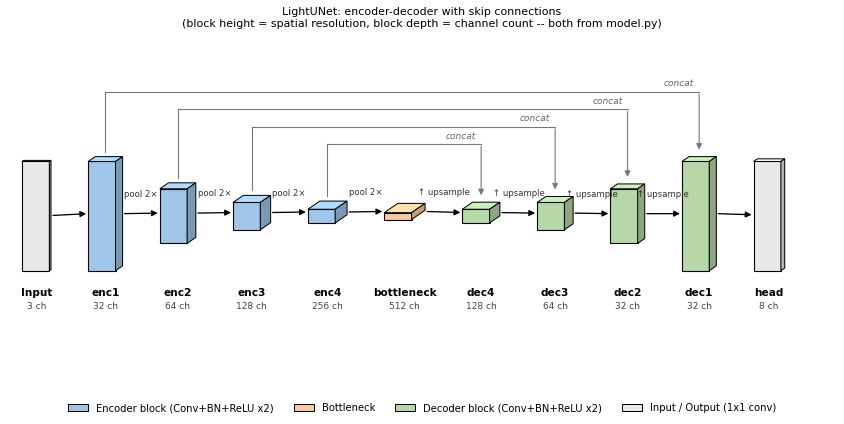

In [16]:
# LightUNet architecture diagram (definition lives in model.py, next
# to the layers it draws -- keeps the diagram in sync with the model).
from model import plot_architecture

plot_architecture()


In [17]:
import torch
from model import LightUNet
from carla_labels import NUM_CLASSES

model = LightUNet(num_classes=NUM_CLASSES)

x   = torch.randn(1, 3, 256, 512)
out = model(x)

params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Input  shape : {tuple(x.shape)}")
print(f"Output shape : {tuple(out.shape)}")
print(f"Parameters   : {params:.1f} M")

Input  shape : (1, 3, 256, 512)
Output shape : (1, 8, 256, 512)
Parameters   : 7.3 M


## 3. Model Training and Evaluation

We train LightUNet from scratch on the baseline training split and never expose it to the sixteen evaluation domains. The optimiser is Adam at a fixed learning rate of 1e-3, run for 50 epochs with a batch size of 8. The loss is per-pixel cross-entropy.

**Class weighting.** After grouping to eight classes, the pixel frequencies stay skewed: road covers a large share of every frame while pedestrian sits near 0.006%. Unweighted cross-entropy lets the frequent classes dominate the gradient, so we weight each class by an ENet-style log-frequency rule, `w_c = 1 / ln(c + f_c)` with `c = 1.02` [[9]](#ref9). This bounds the weights, since inverse frequency would assign the pedestrian class a weight near 1900 and destabilise training, while pushing the rare classes.

**Checkpoint selection.** We hold out a contiguous time-tail of each training town as an in-distribution validation split and keep the checkpoint with the highest validation mIoU rather than the lowest training loss. Training loss keeps falling as the model fits the training towns, so the lowest-loss epoch is the most over-fit one; validation mIoU peaks and then plateaus, and we save that peak (epoch 36). The sixteen domain blocks play no part in training or selection.

**Metric.** We report mean Intersection-over-Union (mIoU) and per-class IoU, following the Cityscapes convention [[7]](#ref7). The IoU of a class is its intersection over the union of predicted and ground-truth pixels; mIoU averages this over the classes whose union is non-empty. In all sixteen domains every one of the eight classes does, so mIoU here is in practice the mean over all eight. We prefer mIoU to pixel accuracy, which road, building, and sky dominate; mIoU gives each class the same weight and exposes a model that ignores the rare ones. Per-class IoU then shows which classes break under a given shift, which the single mIoU number hides. Void (255) pixels enter neither intersection nor union. We accumulate intersection and union counts across a whole domain and divide once, rather than averaging per-frame IoUs, so rare classes are not distorted by small per-batch counts.

**Evaluation protocol.** We run the selected checkpoint on each of the sixteen domains, about 600 frames per domain, batch size 8, with no augmentation so the scores stay reproducible. Block A (training maps and weather, different spawn point) is the in-distribution upper bound; a domain's mIoU drop relative to its block's reference measures the cost of its shift (V1 for the same-map Blocks B and D, the Block A mean for Block C, and the same town's ClearNoon run for Block E, so references stay map-matched wherever possible). Comparing those drops across blocks ranks which shift type is most damaging, the degradation-measurement protocol used by SHIFT [[3]](#ref3).

## 4. ROS 2 Integration

We deploy the trained LightUNet in `acdcrp_segmentation` as separate inference and evaluation nodes, so model execution does not depend on ground-truth arrival. Both use the eight reduced classes of the offline study and ignore target label 255.

**Inference.** The inference node decodes each compressed RGB image, resizes it to 256 by 512 pixels with `INTER_AREA`, applies ImageNet normalisation and runs the frozen checkpoint. It publishes the per-pixel argmax as a `mono8` mask, with an optional colourised view. Each prediction inherits the RGB timestamp and frame ID so the evaluator can associate it with ground truth. Checkpoint, device and topic names are ROS parameters.

**Synchronisation.** The evaluation node pairs predictions with semantic-camera images using `ApproximateTimeSynchronizer` (queue size 20, tolerance 0.15 s) and sensor-data QoS. This accommodates small timestamp differences between streams, but does not guarantee that every frame is evaluated.

| Topic (default) | Type / encoding | Content |
|---|---|---|
| `/carla/ego_vehicle/rgb/image/compressed` | `CompressedImage` | RGB input |
| `/carla/ego_vehicle/segmentation/image/compressed` | `CompressedImage` | Ground-truth input |
| `/acdcrp/prediction/mask` | `Image`, `mono8` | Predicted class IDs |
| `/acdcrp/prediction/color` | `Image`, `rgb8` | Colourised prediction |
| `/acdcrp/evaluation/frame_miou` | `Float32` | Current-pair mIoU |
| `/acdcrp/evaluation/cumulative_miou` | `Float32` | Accumulated mIoU |
| `/acdcrp/evaluation/per_class_iou` | `Float32MultiArray` | Accumulated IoU in class-ID order; `-1` for zero union |
| `/acdcrp/evaluation/ground_truth_color`, `/acdcrp/evaluation/overlay` | `Image`, `rgb8` | Ground truth and error visualisation |

**Ground-truth decoding.** After decompressing the semantic image, we resize it with nearest-neighbour interpolation, match the selected RGB pixels to the CARLA Cityscapes palette, and remap raw IDs to the eight classes. Resizing first skips palette matching for pixels that would be discarded, and it preserves the decoded mask: nearest-neighbour resizing selects pixels without changing their colours, so it commutes with the pointwise mappings, which area or bilinear interpolation would break.

**Metric.** The evaluator accumulates class intersections and unions over valid pixels in all evaluated pairs, following Methodology Section 3, so cumulative mIoU is not an average of frame mIoUs. Zero-union classes appear as `N/A` in tables. A hand-computed ignore-label test in `report_repro.py` checks the counting rule: intersections `[1, 2, 1, 0, 0, 0, 0, 0]` and unions `[2, 3, 1, 0, 0, 0, 0, 0]` give mIoU 0.7222.


# Experiments

Every experiment below ran in the provided ROS 2 Docker environment on the `rhea5` compute node, following the methodology above.


## 1. Synthetic Dataset Generation

We generated every dataset with **CARLAB** on the shared `rhea5` compute node.

**Training dataset.** Merging the three 30-minute ClearNoon recordings (Methodology Section 1.2) with `prepare_datasets.py` yields **5,526 frames**; holding out the last 15% of each town as a contiguous validation time-tail leaves **4,697 train / 829 val**.

**Evaluation domains.** The sixteen 10-minute recordings yield about 600 frames each, ~9,600 in total. The sensor configuration files sit in the repository root: `sensors-config.json` for the standard runs, and `sensors-V11-low-mount.json`, `sensors-V12-pitch-down.json`, `sensors-V13-wide-fov.json` for Block D.


## 2. Data Pipeline and Pre-processing

**Extraction.** We processed each MCAP recording with `data_extraction.py` as described in Methodology Section 2, passing `--every-nth 10` to subsample from 10 Hz to 1 Hz:

```
python data_extraction.py \
    --input /work/carlab/users/acdc-rp-buriachenko/data/<recording>.mcap \
    --output data/extracted/T1 --every-nth 10
```

**Merging training splits.** After extracting T1, T2, and T3 on their own, we ran `prepare_datasets.py` to merge them into `data/train/` and a held-out `data/val/` (the last 15% of each town) with filenames unique across towns, ready for `SegmentationDataset`.

**Verification.** We checked that every label file in `data/train/labels/` holds only values in `[0, 7]` plus the 255 ignore value, confirming no raw CARLA IDs slipped through the remapping. The cell below reports **4,697 label files pass**.

**Transforms.** The reported baseline trains on resized, ImageNet-normalised frames without augmentation; the `augment` flag selects the `photo`, `geo`, or `full` variant from the Dataset and Transforms section.


## 3. Training and Evaluation Runs

We trained the baseline in the cell below on an NVIDIA A40 of the `rhea5` node with the Methodology Section 3 recipe and no augmentation. Validation mIoU on the held-out time-tail peaked at 0.7390 in epoch 36 and plateaued afterwards, so we selected the epoch-36 checkpoint for evaluation. The cell renders the loss and validation-mIoU curves after the last epoch.


Device : cuda
Train  : 4697 samples  |  587 batches/epoch
Val    : 829 samples (in-distribution, for checkpoint selection)
Class weights: [2.66, 6.64, 7.66, 11.14, 8.27, 50.36, 32.74, 8.29]
Model  : LightUNet  |  7.3M parameters
Found existing checkpoint (epoch 36, val_mIoU 0.7390) in checkpoints/ -- skipping training and loading its saved history.
Delete checkpoints/ (or move it aside) to force a fresh training run.

Best val mIoU : 0.7390 (epoch 36)
Saved         -> checkpoints/last_model.pth  +  best_model.pth


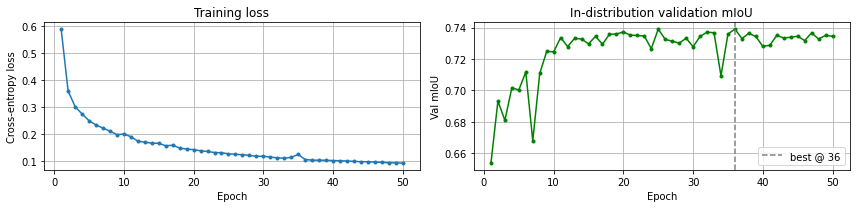

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import tqdm
from pathlib import Path
from torch.utils.data import DataLoader
import torch.multiprocessing as mp
mp.set_sharing_strategy('file_system')
from dataset import SegmentationDataset, build_dataloaders, compute_class_weights
from model import LightUNet
from evaluation import evaluate_model
from carla_labels import NUM_CLASSES

# Config 
EPOCHS      = 50
BATCH_SIZE  = 8
LR          = 1e-3
SAVE_DIR    = Path("checkpoints")
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SAVE_DIR.mkdir(exist_ok=True)
print(f"Device : {DEVICE}")

# Data
train_ds = SegmentationDataset(Path("data/train"), split="train", augment=False)  # raw baseline
val_ds   = SegmentationDataset(Path("data/val"),   split="val")
train_loader, _ = build_dataloaders(
    train_ds, val_datasets={}, batch_size=BATCH_SIZE,
    num_workers=0,    
    pin_memory=False,
)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=False)
print(f"Train  : {len(train_ds)} samples  |  {len(train_loader)} batches/epoch")
print(f"Val    : {len(val_ds)} samples (in-distribution, for checkpoint selection)")

# Model 
model     = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
class_weights = compute_class_weights("data/train/labels", NUM_CLASSES).to(DEVICE)
print("Class weights:", [round(w, 2) for w in class_weights.tolist()])
criterion = nn.CrossEntropyLoss(weight=class_weights, ignore_index=255)
optimizer = optim.Adam(model.parameters(), lr=LR)

params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model  : LightUNet  |  {params:.1f}M parameters")

# Training loop -- skipped if a checkpoint already exists, so re-running this
# cell (e.g. via Run All) reproduces the report from the saved model instead
# of training a new, unseeded run that would not match the numbers below.
if (SAVE_DIR / "best_model.pth").exists() and (SAVE_DIR / "last_model.pth").exists():
    best_ckpt  = torch.load(SAVE_DIR / "best_model.pth", map_location=DEVICE)
    last_ckpt  = torch.load(SAVE_DIR / "last_model.pth", map_location=DEVICE)
    best_miou    = best_ckpt["val_miou"]
    best_epoch   = best_ckpt["epoch"]
    train_losses = last_ckpt["train_losses"]
    val_mious    = last_ckpt["val_mious"]
    print(f"Found existing checkpoint (epoch {best_epoch}, val_mIoU {best_miou:.4f}) "
          f"in {SAVE_DIR}/ -- skipping training and loading its saved history.")
    print(f"Delete {SAVE_DIR}/ (or move it aside) to force a fresh training run.")
else:
    best_miou    = -1.0
    best_epoch   = 0
    train_losses = []
    val_mious    = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        train_losses.append(avg_loss)

        # Checkpoint selection on the held-out in-distribution val split.
        val_miou = evaluate_model(model, val_loader, num_classes=NUM_CLASSES, device=DEVICE)["mIoU"]
        val_mious.append(val_miou)
        print(f"Epoch {epoch:3d}/{EPOCHS}  loss={avg_loss:.4f}  val_mIoU={val_miou:.4f}")

        if val_miou > best_miou:
            best_miou  = val_miou
            best_epoch = epoch
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_miou": best_miou,
                "train_losses": train_losses,
                "val_mious": val_mious,
            }, SAVE_DIR / "best_model.pth")

    # Save final checkpoint
    torch.save({
        "epoch": EPOCHS,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_losses": train_losses,
        "val_mious": val_mious,
    }, SAVE_DIR / "last_model.pth")

print(f"\nBest val mIoU : {best_miou:.4f} (epoch {best_epoch})")
print(f"Saved         -> {SAVE_DIR / 'last_model.pth'}  +  best_model.pth")

# Curves: training loss and validation mIoU
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
ax1.plot(range(1, EPOCHS + 1), train_losses, marker='o', markersize=3)
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Cross-entropy loss")
ax1.set_title("Training loss"); ax1.grid(True)
ax2.plot(range(1, EPOCHS + 1), val_mious, marker='o', markersize=3, color="green")
ax2.axvline(best_epoch, ls="--", color="grey", label=f"best @ {best_epoch}")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Val mIoU")
ax2.set_title("In-distribution validation mIoU"); ax2.grid(True); ax2.legend()
plt.tight_layout()
plt.show()


The next cell loads the epoch-36 checkpoint and scores it on all sixteen extracted domains. It prints the per-domain mIoU summary and draws the per-class IoU heatmap.


Loaded checkpoint (epoch 36)
Using cached results from checkpoints/eval_16_domains.json (delete it to re-evaluate)
V1  Block A  Town10HD  ClearNoon               mIoU=0.6832
V2  Block A  Town01    ClearNoon               mIoU=0.7433
V3  Block A  Town05    ClearNoon               mIoU=0.7491
V4  Block B  Town10HD  WetNoon                 mIoU=0.6347
V5  Block B  Town10HD  HardRainNoon            mIoU=0.5381
V6  Block B  Town10HD  ClearSunset             mIoU=0.6281
V7  Block B  Town10HD  ClearNight              mIoU=0.2333
V8  Block C  Town02    ClearNoon               mIoU=0.6832
V9  Block C  Town03    ClearNoon               mIoU=0.6447
V10 Block C  Town04    ClearNoon               mIoU=0.6422
V11 Block D  z=1.5m                            mIoU=0.4768
V12 Block D  pitch=35°                         mIoU=0.3411
V13 Block D  FOV=110°                          mIoU=0.5856
V14 Block E  Town03  HardRainNoon              mIoU=0.4905
V15 Block E  Town04  ClearNight                mIoU=0.2211


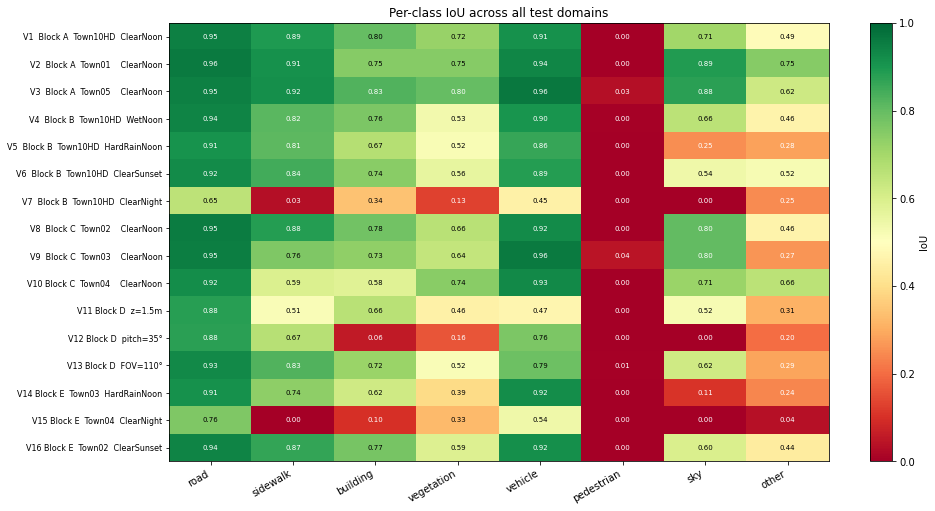

In [19]:
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from pathlib import Path

from dataset import SegmentationDataset
from model import LightUNet
from evaluation import evaluate_model
from carla_labels import REDUCED_CLASSES

DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from carla_labels import NUM_CLASSES

# Load checkpoint
checkpoint = torch.load("checkpoints/best_model.pth", map_location=DEVICE)
model = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded checkpoint (epoch {checkpoint['epoch']})")

# Test domains 
TEST_DOMAINS = {
    # Block A - in-distribution
    "V1  Block A  Town10HD  ClearNoon":  Path("data/extracted/V1"),
    "V2  Block A  Town01    ClearNoon":  Path("data/extracted/V2"),
    "V3  Block A  Town05    ClearNoon":  Path("data/extracted/V3"),
    # Block B - weather shift
    "V4  Block B  Town10HD  WetNoon":       Path("data/extracted/V4"),
    "V5  Block B  Town10HD  HardRainNoon":  Path("data/extracted/V5"),
    "V6  Block B  Town10HD  ClearSunset":   Path("data/extracted/V6"),
    "V7  Block B  Town10HD  ClearNight":    Path("data/extracted/V7"),
    # Block C - map shift
    "V8  Block C  Town02    ClearNoon":  Path("data/extracted/V8"),
    "V9  Block C  Town03    ClearNoon":  Path("data/extracted/V9"),
    "V10 Block C  Town04    ClearNoon":  Path("data/extracted/V10"),
    # Block D - camera shift
    "V11 Block D  z=1.5m":    Path("data/extracted/V11"),
    "V12 Block D  pitch=35°": Path("data/extracted/V12"),
    "V13 Block D  FOV=110°":  Path("data/extracted/V13"),
    # Block E - combined shift
    "V14 Block E  Town03  HardRainNoon": Path("data/extracted/V14"),
    "V15 Block E  Town04  ClearNight":   Path("data/extracted/V15"),
    "V16 Block E  Town02  ClearSunset":  Path("data/extracted/V16"),
}

# Evaluate all domains -- reuses checkpoints/eval_16_domains.json while it is
# newer than the checkpoint; delete that file to force a fresh evaluation.
CKPT  = Path("checkpoints/best_model.pth")
CACHE = CKPT.parent / "eval_16_domains.json"
cached = (json.loads(CACHE.read_text())
          if CACHE.exists() and CACHE.stat().st_mtime >= CKPT.stat().st_mtime else {})
if cached:
    print(f"Using cached results from {CACHE} (delete it to re-evaluate)")

all_results = {}
for label, data_path in TEST_DOMAINS.items():
    dom = label.split()[0]
    if dom in cached:
        res = cached[dom]
    elif not data_path.exists():
        print(f"SKIP {label} — not extracted yet")
        continue
    else:
        ds     = SegmentationDataset(data_path, split="val")
        loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=0, pin_memory=False)
        res    = evaluate_model(model, loader, num_classes=NUM_CLASSES, device=DEVICE)
    all_results[label] = res
    print(f"{label:<45s}  mIoU={res['mIoU']:.4f}")

if not cached and len(all_results) == len(TEST_DOMAINS):
    CACHE.write_text(json.dumps(
        {label.split()[0]: {"mIoU": r["mIoU"], "per_class_iou": r["per_class_iou"]}
         for label, r in all_results.items()}, indent=2))

# Summary table
print("\n" + "="*60)
print(f"{'Domain':<45s}  mIoU")
print("="*60)
for label, res in all_results.items():
    print(f"{label:<45s}  {res['mIoU']:.4f}")

# Per-class IoU heatmap 
if all_results:
    class_names = list(REDUCED_CLASSES.values())
    domain_names = [k.strip() for k in all_results.keys()]
    matrix = np.array([[res["per_class_iou"].get(c, 0) for c in class_names]
                        for res in all_results.values()])

    fig, ax = plt.subplots(figsize=(14, max(4, len(domain_names) * 0.45)))
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=30, ha="right")
    ax.set_yticks(range(len(domain_names))); ax.set_yticklabels(domain_names, fontsize=8)
    for i in range(len(domain_names)):
        for j in range(len(class_names)):
            ax.text(j, i, f"{matrix[i,j]:.2f}", ha="center", va="center", fontsize=7,
                    color="black" if 0.3 < matrix[i,j] < 0.8 else "white")
    plt.colorbar(im, ax=ax, label="IoU")
    ax.set_title("Per-class IoU across all test domains", fontsize=12)
    plt.tight_layout()
    plt.show()


In [20]:
# Augmentation variants for the ablation in the Evaluation section: the baseline
# recipe and checkpoint selection, differing only in the training transform.
# Each is trained with train.py (about as long as the baseline) and skipped while
# its checkpoint exists; delete checkpoints_<variant>/ to retrain it.
import os
import subprocess
import sys
from pathlib import Path

for variant in ("photo", "geo", "full"):
    save_dir = Path(f"checkpoints_{variant}")
    if (save_dir / "best_model.pth").exists():
        print(f"{variant:<5s}: checkpoint found in {save_dir}/, skipping training")
        continue
    cmd = [sys.executable, "train.py", "--data", "data/train",
           "--augment", variant, "--save-dir", str(save_dir)]
    print("Running:", " ".join(cmd))
    with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                          env={**os.environ, "PYTHONUNBUFFERED": "1"}) as proc:
        for line in proc.stdout:
            if line.strip() and "%|" not in line:   # skip tqdm progress-bar redraws
                print(line, end="")
    if proc.returncode != 0:
        raise RuntimeError(f"train.py failed for the {variant} variant")

photo: checkpoint found in checkpoints_photo/, skipping training
geo  : checkpoint found in checkpoints_geo/, skipping training
full : checkpoint found in checkpoints_full/, skipping training


## 4. ROS 2 Replay and Live Runs

We tested the package in two complementary settings. **Replay** passed ten stored V1 pairs through the ROS nodes to check decoding, timestamp matching and metric counts on known inputs. **Live** connected the same nodes to CARLAB to measure online inference and evaluation. Each subsection can run without the earlier training and analysis sections, using a prepared ROS environment; cells within the selected subsection execute in order.

### 4.1 Replay Validation


In [1]:
import os
import sys
import platform
from pathlib import Path

print("System:", platform.system())
print("Host:", platform.node())
print("Python:", sys.executable)
print("Working directory:", Path.cwd())
print("ROS Jazzy installed:", Path("/opt/ros/jazzy/setup.bash").is_file())
print("ROS_DISTRO:", os.environ.get("ROS_DISTRO", "not set"))

System: Linux
Host: 0cfb149c9fdb
Python: /home/dockeruser/.venvs/acdcrp-notebook/bin/python
Working directory: /acdc
ROS Jazzy installed: True
ROS_DISTRO: jazzy


**Setup.** We used the frozen epoch-36 checkpoint, `live_checkpoints/best_model.pth`, in the project ROS 2 Jazzy container. The executed ROS validation used Python 3.12, PyTorch 2.5.0 with CUDA 12.4, NumPy 1.26.4 and OpenCV 4.6.0; the independent offline comparison used Albumentations 1.3.1. Replay used Fast DDS on domain 42 and private topics to reduce interference from other experiments. Each run recorded environment information, source hashes, the checkpoint SHA-256 and results under a timestamped `report_artifacts` directory.

The configuration selects V1 image/label pairs 000000 to 000009 from `ros2_test_samples/V1`, with `data/extracted/V1` as a fallback.


In [4]:
from pathlib import Path

project = Path(
    "/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation"
)

print("Project directory exists:", project.is_dir())

for name in (
    "report.ipynb",
    "report_repro.py",
    "ros_report_runner.py",
    "ros2_ws",
    "live_checkpoints/best_model.pth",
):
    print(f"{name}: {(project / name).exists()}")

Project directory exists: True
report.ipynb: True
report_repro.py: True
ros_report_runner.py: True
ros2_ws: True
live_checkpoints/best_model.pth: True


In [7]:
import sys
import subprocess
import numpy as np

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        f"numpy=={np.__version__}",
        "scikit-image==0.24.0",
        "scikit-learn==1.5.2",
    ],
    check=True,
)

import albumentations
from albumentations.pytorch import ToTensorV2

print("Albumentations:", albumentations.__version__)
print("Offline transforms import OK")

INFO: pip is looking at multiple versions of tifffile to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of tifffile to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 29.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 42.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 318.0/318.0 kB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.0/244.0 kB 33.9 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
qudida 0.0.4 requires opencv-python-headless>=4.0.1, which is not installed.
albumentations 1.3.1 requires opencv-python-headless>=4.1.1, which is not installed.


Albumentations: 1.3.1
Offline transforms import OK


In [8]:
import sys
import subprocess

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--no-deps",
        "albumentations==1.3.1",
        "qudida==0.0.4",
    ],
    check=True,
)

import albumentations
from albumentations.pytorch import ToTensorV2

print("Albumentations:", albumentations.__version__)
print("Offline transforms import OK")

Albumentations: 1.3.1
Offline transforms import OK


In [9]:
# ROS-only configuration and imports; independent of every earlier notebook cell.
import os
import sys
import json
import shlex
import subprocess
import importlib.util
from pathlib import Path
from datetime import datetime, timezone

ROS_PROJECT_DIR = "/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation"
ROS_MODE = "replay"
ROS_DEVICE = "cuda"
ROS_SECONDS = 60
ROS_DOMAIN = 42 if ROS_MODE == 'replay' else 0
ZENOH_ENDPOINT = os.environ.get('ACDCRP_ZENOH_ENDPOINT', '')  # live: tcp/<your-router>:7447
assert ROS_MODE in ('replay', 'live')
candidates = [Path(ROS_PROJECT_DIR or os.environ.get('ACDCRP_TOPIC_ROOT', '.')).resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in candidates if (p / 'report_repro.py').is_file() and (p / 'ros2_ws').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Set ROS_PROJECT_DIR to the Topic 14 directory containing the report helper scripts and ros2_ws.')
sys.path.insert(0, str(ROOT))
ROS_CHECKPOINT = ROOT / 'live_checkpoints/best_model.pth'  # Edit if your frozen checkpoint is elsewhere.
if not ROS_CHECKPOINT.is_file():
    ROS_CHECKPOINT = ROOT / 'checkpoints/best_model.pth'  # same epoch-36 file (identical SHA-256)
ROS_SAMPLES = ROOT / 'ros2_test_samples/V1'
if not ROS_SAMPLES.is_dir():
    ROS_SAMPLES = ROOT / 'data/extracted/V1'
if not ROS_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Provide the trusted frozen model checkpoint: {ROS_CHECKPOINT}')
dependencies = ['numpy', 'cv2', 'torch', 'matplotlib', 'IPython']
if ROS_MODE == 'replay':
    dependencies += ['albumentations', 'torchvision']  # Used by the independent dataset transform.
missing = [name for name in dependencies if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError('Select the configured project Python kernel; missing dependencies: ' + ', '.join(missing))
from report_repro import save_json, sha256, sample_pairs, environment
if ROS_MODE == 'replay':
    sample_pairs(ROS_SAMPLES)
RUN_DIR = ROOT / 'report_artifacts' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
save_json(RUN_DIR / 'environment.json', environment(ROOT))
save_json(RUN_DIR / 'checkpoint_manifest.json', {'checkpoint': str(ROS_CHECKPOINT), 'sha256': sha256(ROS_CHECKPOINT)})
print('Standalone ROS mode:', ROS_MODE, '| device:', ROS_DEVICE)
print('Artifacts:', RUN_DIR)


Standalone ROS mode: replay | device: cuda
Artifacts: /acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/report_artifacts/20260908T204259_591762Z


**Replay input.** We encoded RGB frames as JPEG at quality 90 and converted the reduced labels to representative raw CARLA IDs in lossless palette PNGs. This exercises the ROS decoder on constructed messages rather than replaying an original sensor recording; the labels do not reproduce live JPEG compression artefacts. The next cell checks that all ten decoded masks match the source labels pixel for pixel and runs a separate offline inference pass for comparison.


In [10]:
# Optional offline cross-check for ROS replay; live mode does not need offline data.
offline_result = None
if ROS_MODE == 'replay':
    from report_repro import offline_validate
    offline_result = offline_validate(ROOT, ROS_CHECKPOINT, ROS_SAMPLES, RUN_DIR / 'offline', ROS_DEVICE)
    print('Checkpoint epoch:', offline_result['epoch'])
    print('Independent offline cumulative mIoU:', offline_result['miou'])
    print('All 10 constructed-label masks matched; metric unit test passed.')
else:
    print('Live mode: using CARLAB inputs directly; no offline dataset or preceding training cells are required.')


Checkpoint epoch: 36
Independent offline cumulative mIoU: 0.598477122412349
All 10 constructed-label masks matched; metric unit test passed.


**Build and run.** The next cells build the package with `colcon` and start inference and evaluation in separate processes. Replay sends one pair at a time and waits for its prediction and evaluation response, so queues cannot build up; timeouts stop an incomplete run, and the evaluation worker exports timestamp pairs and final counts for the next cell to verify.


In [11]:
# Build and source in a Linux subprocess; notebook kernel environment is not mutated by source.
import os
import shlex
import subprocess
import sys
if sys.platform != 'linux' or not Path('/opt/ros/jazzy/setup.bash').is_file():
    raise RuntimeError('ROS experiments must run in the project Linux ROS 2 Jazzy container.')
ROS_ENV = os.environ.copy()
ROS_ENV['ROS_DOMAIN_ID'] = str(ROS_DOMAIN)
if ROS_MODE == 'replay':
    ROS_ENV['RMW_IMPLEMENTATION'] = 'rmw_fastrtps_cpp'
    ROS_ENV['FASTDDS_BUILTIN_TRANSPORTS'] = 'UDPv4'
    ROS_ENV.pop('ZENOH_CONFIG_OVERRIDE', None)
else:
    if not ZENOH_ENDPOINT.startswith('tcp/'):
        raise ValueError('Set ZENOH_ENDPOINT to the reachable CARLAB router, e.g. tcp/router-name:7447.')
    ROS_ENV['RMW_IMPLEMENTATION'] = 'rmw_zenoh_cpp'
    ROS_ENV['ZENOH_CONFIG_OVERRIDE'] = 'connect/endpoints=[' + __import__('json').dumps(ZENOH_ENDPOINT) + ']'
    ROS_ENV.pop('FASTDDS_BUILTIN_TRANSPORTS', None)
workspace = ROOT / 'ros2_ws'
build_command = 'source /opt/ros/jazzy/setup.bash && colcon build --packages-select acdcrp_segmentation'
with (RUN_DIR / 'build.log').open('w') as log:
    subprocess.run(['bash', '-c', build_command], cwd=workspace, env=ROS_ENV,
                   stdout=log, stderr=subprocess.STDOUT, check=True, timeout=300)
ROS_SOURCE = 'source /opt/ros/jazzy/setup.bash && source ' + shlex.quote(str(workspace / 'install/setup.bash')) + ' && '
probe = 'import rclpy, cv_bridge, message_filters, torch; from acdcrp_segmentation import utils; print(utils.__file__)'
subprocess.run(['bash', '-c', ROS_SOURCE + shlex.join([sys.executable, '-c', probe])], env=ROS_ENV, check=True, timeout=30)
print((RUN_DIR / 'build.log').read_text())


/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/ros2_ws/install/acdcrp_segmentation/lib/python3.12/site-packages/acdcrp_segmentation/utils.py
Starting >>> acdcrp_segmentation
Finished <<< acdcrp_segmentation [1.09s]

Summary: 1 package finished [1.24s]



In [12]:
# Finite actual ROS-node experiment. Private outputs avoid mixing with old evaluation nodes.
import signal
import time
ROS_RUN_DIR = RUN_DIR / ('ros_' + ROS_MODE)
command = [sys.executable, str(ROOT / 'ros_report_runner.py'), '--mode', ROS_MODE,
           '--checkpoint', str(ROS_CHECKPOINT), '--samples', str(ROS_SAMPLES),
           '--output', str(ROS_RUN_DIR), '--device', ROS_DEVICE, '--seconds', str(ROS_SECONDS)]
with (RUN_DIR / 'runner.log').open('w') as log:
    process = subprocess.Popen(['bash', '-c', ROS_SOURCE + 'exec ' + shlex.join(command)],
                               cwd=ROOT, env=ROS_ENV, stdout=log, stderr=subprocess.STDOUT,
                               start_new_session=True)
    try:
        result_code = process.wait(timeout=600 + ROS_SECONDS)
        if result_code:
            raise RuntimeError(f'ROS experiment failed ({result_code}); inspect {RUN_DIR / "runner.log"}')
    finally:
        if process.poll() is None:
            os.killpg(process.pid, signal.SIGINT)
            try:
                process.wait(timeout=45)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid, signal.SIGKILL)
                process.wait()
print((RUN_DIR / 'runner.log').read_text())


{
  "output": "/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/report_artifacts/20260908T204259_591762Z/ros_replay",
  "pairs": 10,
  "rates": {
    "rgb": {
      "received": 10,
      "window_seconds": 2.1628575411159545,
      "hz": 4.623513019188666
    },
    "gt": {
      "received": 10,
      "window_seconds": 2.1628575411159545,
      "hz": 4.623513019188666
    },
    "prediction": {
      "received": 10,
      "window_seconds": 2.1628575411159545,
      "hz": 4.623513019188666
    },
    "metric": {
      "received": 10,
      "window_seconds": 2.1628575411159545,
      "hz": 4.623513019188666
    }
  }
}



**Replay check.** We compare the evaluated timestamps with the ten input timestamps and independently construct a confusion matrix from the received prediction masks and corresponding labels. Its integer intersections and unions must equal the ROS accumulator exactly. The separately inferred offline mIoU is a second comparison, for which preprocessing and floating-point differences may produce a small numerical gap.


PASS: 10 timestamp-matched pairs; ROS metric counts agree exactly with an independent confusion matrix of received masks.
Separately inferred offline mIoU: 0.598477122412349 | ROS-minus-offline: 2.182857204435784e-06


**Fresh replay: 10 pairs, mIoU 0.598479**

| Class | Fresh cumulative IoU |
|---|---:|
| road | 0.936172 |
| sidewalk | 0.646792 |
| building | 0.629454 |
| vegetation | 0.608824 |
| vehicle | 0.696227 |
| pedestrian | N/A |
| sky | N/A |
| other | 0.073407 |


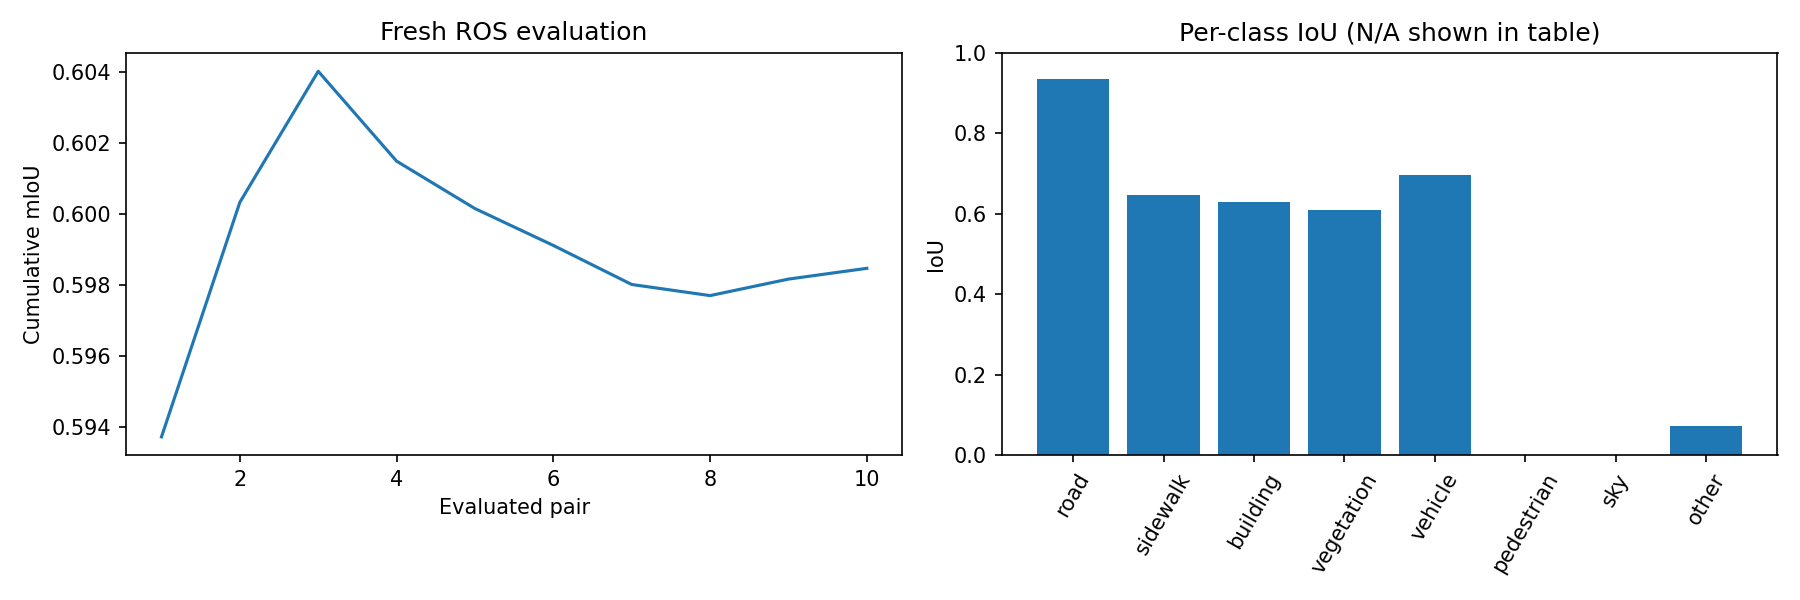

Decoder median: old=389.65 ms, new=99.10 ms, ratio=3.93x
Benchmark input: constructed PNG labels, not live JPEG
Artifacts: /acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/report_artifacts/20260908T204259_591762Z/ros_replay
Save this notebook to retain its fresh tables and figures. Historical prose is not overwritten.


In [15]:
# Compute, persist and display fresh ROS results from the exported accumulator.
import json
import numpy as np
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import display, Markdown
final = json.loads((ROS_RUN_DIR / 'evaluation_final.json').read_text())
observed = json.loads((ROS_RUN_DIR / 'observation.json').read_text())
assert observed['completed'], 'Incomplete experiment; do not report as a successful run.'
intersection = np.asarray(final['intersection'], dtype=np.int64)
union = np.asarray(final['union'], dtype=np.int64)
iou = np.divide(intersection, union, out=np.full(8, np.nan), where=union > 0)
miou = float(np.nanmean(iou))
pair_rows = [json.loads(line) for line in (ROS_RUN_DIR / 'pairs.jsonl').read_text().splitlines()]
assert len(pair_rows) == final['pair_count'], 'Incomplete exported pair log'
if ROS_MODE == 'replay':
    # Verify shared metrics from actual received masks, independently of model inference.
    import cv2
    confusion = np.zeros((8, 8), dtype=np.int64)
    for index, (_, label_path) in enumerate(sample_pairs(ROS_SAMPLES)):
        target = cv2.resize(cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED), (512, 256), interpolation=cv2.INTER_NEAREST)
        prediction = np.load(ROS_RUN_DIR / f'prediction_{index:06d}.npy')
        valid = target != 255
        confusion += np.bincount(target[valid].astype(np.int64) * 8 + prediction[valid], minlength=64).reshape(8, 8)
    np.save(ROS_RUN_DIR / 'independent_confusion.npy', confusion)
    expected_intersection = np.diag(confusion)
    expected_union = confusion.sum(0) + confusion.sum(1) - expected_intersection
    np.testing.assert_array_equal(intersection, expected_intersection)
    np.testing.assert_array_equal(union, expected_union)
    assert final['pair_count'] == 10
    assert all(row['prediction_stamp'] == row['truth_stamp'] for row in pair_rows)
    print('PASS: 10 timestamp-matched pairs; ROS metric counts agree exactly with an independent confusion matrix of received masks.')
    print('Separately inferred offline mIoU:', offline_result['miou'], '| ROS-minus-offline:', miou - offline_result['miou'])
summary = {'mode': ROS_MODE, 'processed_pairs': final['pair_count'], 'miou': miou,
           'per_class_iou': [float(x) if np.isfinite(x) else None for x in iou],
           'observer_rates': observed['rates'], 'checkpoint_sha256': sha256(ROS_CHECKPOINT)}
save_json(ROS_RUN_DIR / 'summary.json', summary)
names = ['road', 'sidewalk', 'building', 'vegetation', 'vehicle', 'pedestrian', 'sky', 'other']
table = '| Class | Fresh cumulative IoU |\n|---|---:|\n'
table += ''.join(f'| {name} | {value:.6f} |\n' if np.isfinite(value) else f'| {name} | N/A |\n' for name, value in zip(names, iou))
display(Markdown(f'**Fresh {ROS_MODE}: {final["pair_count"]} pairs, mIoU {miou:.6f}**\n\n' + table))
fig = Figure(figsize=(12, 4))
canvas = FigureCanvasAgg(fig)
axes = fig.subplots(1, 2)
axes[0].plot([r['pair'] for r in pair_rows], [r['miou'] for r in pair_rows])
axes[0].set(xlabel='Evaluated pair', ylabel='Cumulative mIoU', title='Fresh ROS evaluation')
axes[1].bar(names, np.nan_to_num(iou))
axes[1].tick_params(axis='x', rotation=60)
axes[1].set(ylabel='IoU', ylim=(0, 1), title='Per-class IoU (N/A shown in table)')
fig.tight_layout()
fig.savefig(ROS_RUN_DIR / 'evaluation.png', dpi=150)
from IPython.display import Image as NotebookImage
display(NotebookImage(filename=str(ROS_RUN_DIR / "evaluation.png")))
fig.clear()
if ROS_MODE == 'live':
    from report_repro import benchmark_captured_live
    benchmark_rows = benchmark_captured_live(ROOT, ROS_RUN_DIR)
else:
    benchmark_rows = offline_result['decoder_trials']
old_ms = float(np.median([r['old_ms'] for r in benchmark_rows]))
new_ms = float(np.median([r['new_ms'] for r in benchmark_rows]))
print(f'Decoder median: old={old_ms:.2f} ms, new={new_ms:.2f} ms, ratio={old_ms/new_ms:.2f}x')
print('Benchmark input:', 'captured live compressed GT' if ROS_MODE == 'live' else 'constructed PNG labels, not live JPEG')
if ROS_MODE == 'live':
    rate_table = '| Stream | Received | Window (s) | Observed Hz |\n|---|---:|---:|---:|\n'
    for stream, values in observed['rates'].items():
        rate_table += f"| {stream} | {values['received']} | {values['window_seconds']:.2f} | {values['hz']:.3f} |\n"
    display(Markdown(rate_table))
print('Artifacts:', ROS_RUN_DIR)
print('Save this notebook to retain its fresh tables and figures. Historical prose is not overwritten.')


### 4.2 Live Validation

We ran CARLAB job `2026-09-08_21-40-19_0` with `acdc_perception.yml`: Town10HD_Opt, ClearNoon, spawn point 1, five vehicles, occupancy 0.2 and no walkers. Both the wall-clock and simulation-time limits were 600 s. The RGB and semantic-camera settings in the CARLAB sensor file (`configs/local/sensors/sensors.json`) match the standard camera of the supplied `sensors-config.json`. Neither camera explicitly sets `sensor_tick`.

The nodes used `rmw_zenoh_cpp` on domain 0 through the CARLAB router, with private output topics. The harness observed messages for 60 wall-clock seconds after the first evaluation result, then benchmarked decoding on ten captured semantic messages. It did not start or stop the CARLAB job.


In [16]:
# LIVE 1/4: independent configuration; never change Replay variables.
def _live_setup(project_dir=None, device='cuda', seconds=60,
                endpoint='tcp/carlab-acdc-rp-wang-local-zenoh-router:7447',
                checkpoint_path=None, job_id=''):
    import importlib.util
    import os
    import sys
    from pathlib import Path
    from datetime import datetime, timezone

    candidates = [Path(project_dir or os.environ.get('ACDCRP_TOPIC_ROOT', '.')).resolve(),
                  *Path.cwd().resolve().parents,
                  Path('/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation')]
    root = next((p for p in candidates if (p / 'report_repro.py').is_file()
                 and (p / 'ros_report_runner.py').is_file() and (p / 'ros2_ws').is_dir()), None)
    if root is None:
        raise FileNotFoundError('Set project_dir to Topic 14 with both report helper scripts and ros2_ws.')
    checkpoint = Path(checkpoint_path).expanduser().resolve() if checkpoint_path else root / 'live_checkpoints/best_model.pth'
    if not checkpoint_path and not checkpoint.is_file():
        checkpoint = root / 'checkpoints/best_model.pth'  # same epoch-36 file (identical SHA-256)
    if not checkpoint.is_file():
        raise FileNotFoundError(f'Provide the trusted frozen checkpoint: {checkpoint}')
    if not 1 <= seconds <= 600 or not endpoint.startswith('tcp/'):
        raise ValueError('Use seconds in [1, 600] and endpoint tcp/<reachable-router>:7447.')
    missing = [name for name in ('numpy', 'cv2', 'torch', 'matplotlib', 'IPython')
               if importlib.util.find_spec(name) is None]
    if missing:
        raise RuntimeError('Use the configured project kernel; missing: ' + ', '.join(missing))
    sys.path.insert(0, str(root))
    from report_repro import environment, save_json, sha256
    run_dir = root / 'report_artifacts/live' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir.mkdir(parents=True, exist_ok=False)
    state = {'root': root, 'checkpoint': checkpoint, 'device': device, 'seconds': seconds,
             'endpoint': endpoint, 'domain': 0, 'job_id': job_id, 'run_dir': run_dir,
             'ros_dir': run_dir / 'ros_live', 'built': False, 'completed': False}
    save_json(run_dir / 'environment.json', environment(root))
    save_json(run_dir / 'live_manifest.json', {
        'checkpoint': str(checkpoint), 'checkpoint_sha256': sha256(checkpoint),
        'device_requested': device, 'seconds': seconds, 'endpoint': endpoint,
        'domain': 0, 'job_id': job_id or None})
    print('Live configuration ready; no ROS nodes started.')
    print('Artifacts:', run_dir)
    return state

LIVE_STATE = _live_setup(
    project_dir='/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation',
    device='cuda',
    seconds=60,
    endpoint='tcp/carlab-acdc-rp-wang-local-zenoh-router:7447',
    job_id='',  # Enter the actual CARLAB job ID when available.
)


Live configuration ready; no ROS nodes started.
Artifacts: /acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/report_artifacts/live/20260908T212156_753454Z


**Build.** The subprocess build checks the installed ROS package and Zenoh middleware before observation.


In [17]:
# LIVE 2/4: build and verify Jazzy/Zenoh in an isolated subprocess environment.
def _live_build(state):
    import os
    import sys
    import json
    import shlex
    import subprocess
    from pathlib import Path

    state['built'] = False
    if sys.platform != 'linux' or not Path('/opt/ros/jazzy/setup.bash').is_file():
        raise RuntimeError('Run this section in the project Linux ROS 2 Jazzy container.')
    env = os.environ.copy()
    env['ROS_DOMAIN_ID'] = str(state['domain'])
    env['RMW_IMPLEMENTATION'] = 'rmw_zenoh_cpp'
    env['ZENOH_CONFIG_OVERRIDE'] = 'connect/endpoints=[' + json.dumps(state['endpoint']) + ']'
    env.pop('FASTDDS_BUILTIN_TRANSPORTS', None)
    workspace = state['root'] / 'ros2_ws'
    command = 'source /opt/ros/jazzy/setup.bash && colcon build --packages-select acdcrp_segmentation'
    with (state['run_dir'] / 'build.log').open('w') as log:
        subprocess.run(['bash', '-c', command], cwd=workspace, env=env, stdout=log,
                       stderr=subprocess.STDOUT, check=True, timeout=300)
    source = 'source /opt/ros/jazzy/setup.bash && source ' + shlex.quote(str(workspace / 'install/setup.bash')) + ' && '
    probe = 'import rclpy, cv_bridge, message_filters, torch; from acdcrp_segmentation import utils; print(utils.__file__)'
    command = source + 'ros2 pkg prefix rmw_zenoh_cpp && ' + shlex.join([sys.executable, '-c', probe])
    subprocess.run(['bash', '-c', command], env=env, check=True, timeout=30)
    state.update(env=env, source=source, built=True)
    print((state['run_dir'] / 'build.log').read_text())

_live_build(LIVE_STATE)


/opt/ros/jazzy
/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/ros2_ws/install/acdcrp_segmentation/lib/python3.12/site-packages/acdcrp_segmentation/utils.py
Starting >>> acdcrp_segmentation
Finished <<< acdcrp_segmentation [1.07s]

Summary: 1 package finished [1.21s]



**Observation.** The run cell starts the ROS workers while the CARLAB task supplies live data and closes them after the observation window.


In [18]:
LIVE_STATE['job_id'] = '2026-09-08_21-40-19_0'

import json as _live_json
from report_repro import save_json as _live_save_json

_live_manifest_path = LIVE_STATE['run_dir'] / 'live_manifest.json'
_live_manifest = _live_json.loads(_live_manifest_path.read_text())
_live_manifest['job_id'] = LIVE_STATE['job_id']
_live_save_json(_live_manifest_path, _live_manifest)

In [19]:
# LIVE 3/4: run only after the CARLAB RGB/semantic streams are active.
def _live_run(state):
    import os
    import sys
    import shlex
    import signal
    import subprocess

    if not state['built']:
        raise RuntimeError('Complete Live setup and build first.')
    if state['ros_dir'].exists():
        raise FileExistsError('This run directory already exists. Keep it; rerun Live setup/build for a new attempt.')
    state['completed'] = False
    command = [sys.executable, str(state['root'] / 'ros_report_runner.py'), '--mode', 'live',
               '--checkpoint', str(state['checkpoint']), '--output', str(state['ros_dir']),
               '--device', state['device'], '--seconds', str(state['seconds'])]
    with (state['run_dir'] / 'runner.log').open('w') as log:
        process = subprocess.Popen(['bash', '-c', state['source'] + 'exec ' + shlex.join(command)],
                                   cwd=state['root'], env=state['env'], stdout=log,
                                   stderr=subprocess.STDOUT, start_new_session=True)
        try:
            result = process.wait(timeout=state['seconds'] + 180)
            if result:
                raise RuntimeError(f'Live worker failed ({result}); inspect {state["run_dir"] / "runner.log"}')
            state['completed'] = True
        finally:
            if process.poll() is None:
                os.killpg(process.pid, signal.SIGINT)
                try:
                    process.wait(timeout=45)
                except subprocess.TimeoutExpired:
                    os.killpg(process.pid, signal.SIGKILL)
                    process.wait()
    print((state['run_dir'] / 'runner.log').read_text())

_live_run(LIVE_STATE)


2026-09-08T21:41:51.864436Z  WARN net-0 ThreadId(02) zenoh::net::runtime::orchestrator: Unable to connect to any locator of scouted peer 254363691b9feb288942c020a1e91b17: [tcp/[::1]:37901]
2026-09-08T21:41:51.864501Z  WARN net-0 ThreadId(02) zenoh::net::runtime::orchestrator: Unable to connect to any locator of scouted peer f05b203f896b92c16ad27783a57ae3a0: [tcp/[::1]:46795]
2026-09-08T21:41:51.864516Z  WARN net-0 ThreadId(02) zenoh::net::runtime::orchestrator: Unable to connect to any locator of scouted peer 4c830958d1172475f6232fde9e6b2492: [tcp/[::1]:36621]
2026-09-08T21:41:51.864528Z  WARN net-0 ThreadId(02) zenoh::net::runtime::orchestrator: Unable to connect to any locator of scouted peer 8f21794cc06c5c34c24b3a3e6afe4100: [tcp/[::1]:40561]
2026-09-08T21:41:52.360710Z  WARN ThreadId(11) zenoh::net::runtime::orchestrator: Scouting delay elapsed before start conditions are met.
{
  "output": "/acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/report_ar

**Evaluation.** The next cell derives IoU from the final accumulator and reports message reception over the observation window.


**Live: 461 evaluated pairs; cumulative mIoU 0.624296**

| Class | Live cumulative IoU |
|---|---:|
| road | 0.964990 |
| sidewalk | 0.844154 |
| building | 0.779696 |
| vegetation | 0.444480 |
| vehicle | 0.923344 |
| pedestrian | 0.000000 |
| sky | 0.568629 |
| other | 0.469073 |


| Stream | Received | Window (s) | Observed Hz |
|---|---:|---:|---:|
| rgb | 898 | 60.01 | 14.965 |
| gt | 897 | 60.01 | 14.949 |
| prediction | 897 | 60.01 | 14.949 |
| metric | 456 | 60.01 | 7.599 |


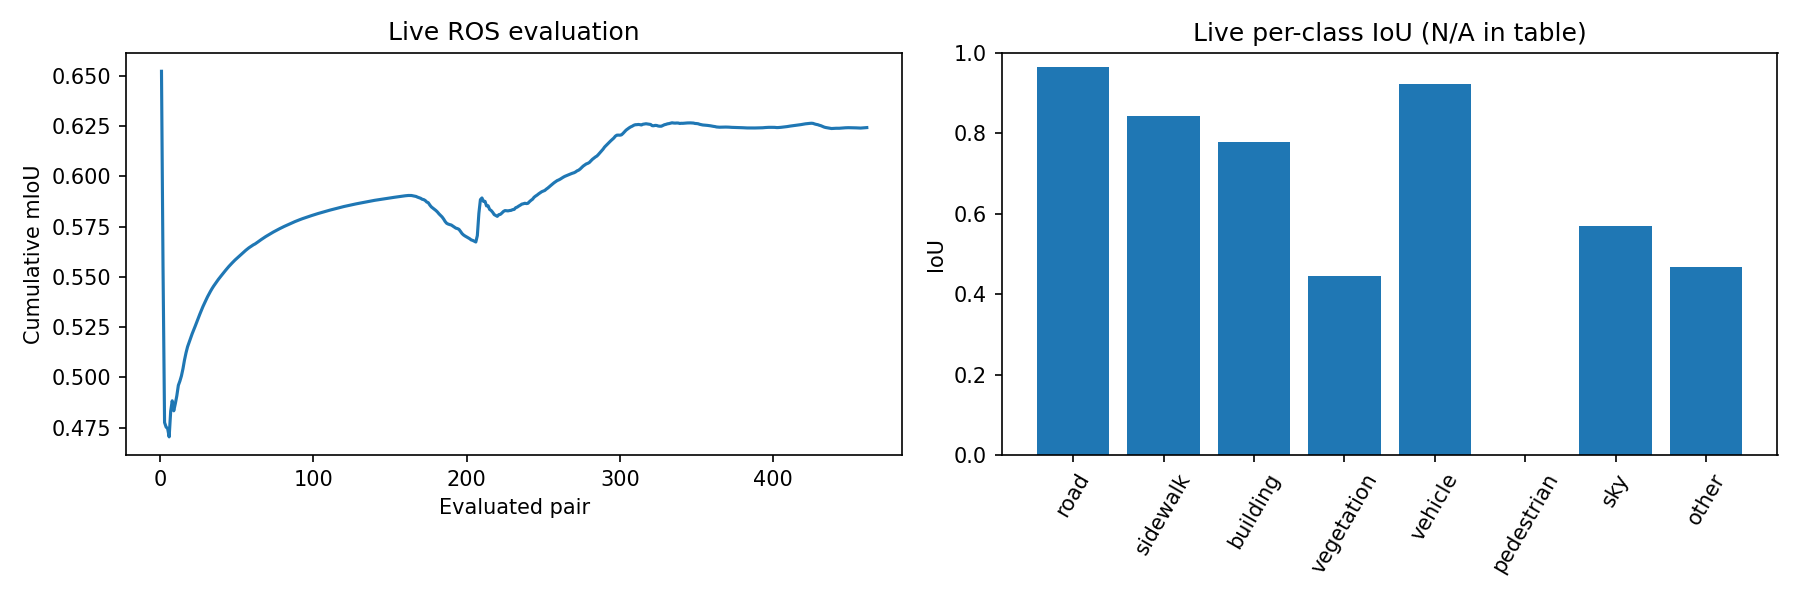

Captured-live decoder median: old=392.67 ms, new=99.96 ms, ratio=3.93x
All ten captured semantic messages produced identical old/new masks.
These are observed live reception rates, not pair-success ratios or historical replay rates.
Artifacts: /acdc/topics/14-Simulation-Based-Performance-Study-of-Semantic-Image-Segmentation/report_artifacts/live/20260908T212156_753454Z/ros_live
Save this Live output; do not overwrite the Replay cells.


In [20]:
# @ LIVE 4/4: fresh Live tables, plots and captured-JPEG decoder validation.
def _live_results(state):
    import json
    import numpy as np
    from matplotlib.figure import Figure
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    from IPython.display import display, Markdown, Image
    from report_repro import save_json, sha256, benchmark_captured_live

    if not state['completed']:
        raise RuntimeError('The Live run must complete successfully before displaying its results.')
    directory = state['ros_dir']
    final = json.loads((directory / 'evaluation_final.json').read_text())
    observed = json.loads((directory / 'observation.json').read_text())
    assert observed['completed'], 'Incomplete observation'
    rows = [json.loads(line) for line in (directory / 'pairs.jsonl').read_text().splitlines()]
    assert len(rows) == final['pair_count'] > 0, 'Incomplete pair log'
    intersection, union = np.asarray(final['intersection']), np.asarray(final['union'])
    iou = np.divide(intersection, union, out=np.full(8, np.nan), where=union > 0)
    if not np.any(union > 0):
        raise ValueError('No valid class union; mIoU is undefined.')
    miou = float(np.nanmean(iou))
    summary = {'mode': 'live', 'pair_count': final['pair_count'], 'miou': miou,
               'per_class_iou': [float(v) if np.isfinite(v) else None for v in iou],
               'observer_rates': observed['rates'], 'job_id': state['job_id'] or None,
               'checkpoint_sha256': sha256(state['checkpoint'])}
    save_json(directory / 'summary.json', summary)
    names = ['road', 'sidewalk', 'building', 'vegetation', 'vehicle', 'pedestrian', 'sky', 'other']
    table = '| Class | Live cumulative IoU |\n|---|---:|\n'
    for name, value in zip(names, iou):
        text = f'{value:.6f}' if np.isfinite(value) else 'N/A'
        table += f'| {name} | {text} |\n'
    display(Markdown(f'**Live: {final["pair_count"]} evaluated pairs; cumulative mIoU {miou:.6f}**\n\n' + table))
    rate_table = '| Stream | Received | Window (s) | Observed Hz |\n|---|---:|---:|---:|\n'
    for stream, values in observed['rates'].items():
        rate_table += f"| {stream} | {values['received']} | {values['window_seconds']:.2f} | {values['hz']:.3f} |\n"
    display(Markdown(rate_table))
    fig = Figure(figsize=(12, 4))
    canvas = FigureCanvasAgg(fig)
    axes = fig.subplots(1, 2)
    axes[0].plot([r['pair'] for r in rows], [r['miou'] for r in rows])
    axes[0].set(xlabel='Evaluated pair', ylabel='Cumulative mIoU', title='Live ROS evaluation')
    axes[1].bar(names, np.nan_to_num(iou))
    axes[1].tick_params(axis='x', rotation=60)
    axes[1].set(ylabel='IoU', ylim=(0, 1), title='Live per-class IoU (N/A in table)')
    fig.tight_layout()
    fig.savefig(directory / 'evaluation.png', dpi=150)
    display(Image(filename=str(directory / 'evaluation.png')))
    fig.clear()
    trials = benchmark_captured_live(state['root'], directory)
    old = float(np.median([t['old_ms'] for t in trials]))
    new = float(np.median([t['new_ms'] for t in trials]))
    print(f'Captured-live decoder median: old={old:.2f} ms, new={new:.2f} ms, ratio={old/new:.2f}x')
    print('All ten captured semantic messages produced identical old/new masks.')
    print('These are observed live reception rates, not pair-success ratios or historical replay rates.')
    print('Artifacts:', directory)
    print('Save this Live output; do not overwrite the Replay cells.')
    return summary

LIVE_SUMMARY = _live_results(LIVE_STATE)


### 4.3 Results

**Replay correctness.** All ten constructed ground-truth masks matched their source labels. All ten evaluated timestamp pairs matched the inputs, and the ROS accumulated counts equalled an independently constructed confusion matrix of the received predictions exactly. ROS mIoU was 0.598479; a separate offline inference pass gave 0.598477, a difference of about 0.0000022. Pedestrian and sky had zero union, so six classes entered the replay mean. This ten-frame check is not an estimate of full-V1 accuracy.

**Live operation.** Over the 60.01 s observation window, the observer received 898 RGB messages (14.965 Hz), 897 ground-truth messages and 897 predictions (both 14.949 Hz), and 456 evaluation messages (7.599 Hz). Predictions kept pace with RGB input while evaluation results arrived at about half the rate; these are received-message rates, not node publication rates, and do not by themselves identify the bottleneck. Across the workers' full lifetime, including callbacks outside this window, the evaluator accumulated 461 pairs with mIoU **0.624296**.

Road (0.965) and vehicle (0.923) had the highest IoUs, while vegetation (0.444) and other (0.469) were substantially lower. Pedestrian IoU was zero despite no walkers being requested; a nonzero union can arise from predicted pixels alone, so this value does not establish pedestrian recall. The offline V1 score (about 0.68) differs from this run in sampling, traffic, class coverage and label encoding, so the gap does not isolate a domain-shift effect.

**Decoder speed-up.** On ten distinct semantic messages captured during this live run, moving resizing before palette matching reduced median decoding time from **392.67 ms to 99.96 ms (3.93x)**. All ten output masks were identical between decoder versions. This measures decoder-only improvement on the captured inputs, not end-to-end acceleration.

**Longer run and limits.** An earlier manual run (`2026-09-07_21-33-23_0`) reached mIoU 0.6476 at its last logged value, after 3,300 evaluated pairs, before its CARLAB job failed during actor cleanup; the bounded run above likewise does not establish error-free shutdown. Neither live session was archived as a complete RGB/GT recording, so rerunning the configuration reproduces the procedure, not the exact input sequence or mIoU. The evidence supports operation in the tested scene, not robustness across the sixteen offline domains.


# Evaluation

## 1. Quantitative Evaluation

The table below lists the mIoU of the selected epoch-36 checkpoint on all sixteen domains, the map-matched reference we measure each domain against (Methodology Section 3), and the resulting shift cost Δ.

| ID | Block | Domain | mIoU | Reference | Δ mIoU |
|----|-------|--------|------|-----------|--------|
| V1 | A | Town10HD, ClearNoon | 0.683 | – | – |
| V2 | A | Town01, ClearNoon | 0.743 | – | – |
| V3 | A | Town05, ClearNoon | 0.749 | – | – |
| V4 | B | Town10HD, WetNoon | 0.635 | V1 (0.683) | −0.049 |
| V5 | B | Town10HD, HardRainNoon | 0.538 | V1 (0.683) | −0.145 |
| V6 | B | Town10HD, ClearSunset | 0.628 | V1 (0.683) | −0.055 |
| V7 | B | Town10HD, ClearNight | 0.233 | V1 (0.683) | −0.450 |
| V8 | C | Town02, ClearNoon | 0.683 | A mean (0.725) | −0.042 |
| V9 | C | Town03, ClearNoon | 0.645 | A mean (0.725) | −0.081 |
| V10 | C | Town04, ClearNoon | 0.642 | A mean (0.725) | −0.083 |
| V11 | D | Town10HD, z = 1.5 m | 0.477 | V1 (0.683) | −0.206 |
| V12 | D | Town10HD, pitch = 35° | 0.341 | V1 (0.683) | −0.342 |
| V13 | D | Town10HD, FOV = 110° | 0.586 | V1 (0.683) | −0.098 |
| V14 | E | Town03, HardRainNoon | 0.491 | V9 (0.645) | −0.154 |
| V15 | E | Town04, ClearNight | 0.221 | V10 (0.642) | −0.421 |
| V16 | E | Town02, ClearSunset | 0.640 | V8 (0.683) | −0.043 |

**Ranking of single shifts.** Night (−0.450) and camera pitch (−0.342) cost the most, followed by camera height (−0.206) and hard rain (−0.145); every other single shift costs less than 0.10. Lighting and viewpoint dominate, weather appearance sits in the middle, and map geometry is the cheapest shift in the study: the model transfers to road layouts it has never seen at a small fraction of the cost of a lighting change on a street it knows.

**Weather costs transfer across maps.** Block E behaves as if the Town10HD weather cost were added onto the unseen-town baseline:

| Domain | Additive prediction | Measured | Deviation |
|--------|--------------------|----------|-----------|
| V14 (Town03 + HardRain) | 0.645 − 0.145 = 0.500 | 0.491 | −0.009 |
| V15 (Town04 + Night) | 0.642 − 0.450 = 0.192 | 0.221 | +0.029 |
| V16 (Town02 + Sunset) | 0.683 − 0.055 = 0.628 | 0.640 | +0.012 |

All deviations stay within 0.03, so at this scale the two shift axes act independently. The largest deviation is V15, where night pushes the model near its floor and the additive prediction undershoots. That deviation is structural rather than evidence against independence: mIoU cannot fall below zero, so additive costs must compress as their sum approaches the floor.

**In-distribution scores spread across maps.** The three Block A scores span 0.683 to 0.749 on training maps under training weather; observation 1 in Section 3 traces the spread to scene statistics, which is why the references above stay within one map wherever possible.

Every score in this report comes from one 10-minute recording per domain. The next cell quantifies the resulting sampling noise with a moving-block bootstrap [[16]](#ref16) over contiguous 30-frame blocks (1000 replicates), which respects the temporal correlation between consecutive frames; the implementation lives in `bootstrap.py`, and the limits paragraph in Section 3 reads the results.

V1   evaluated: 642 frames, mIoU 0.6832
V2   evaluated: 644 frames, mIoU 0.7433
V3   evaluated: 642 frames, mIoU 0.7491
V4   evaluated: 644 frames, mIoU 0.6347
V5   evaluated: 645 frames, mIoU 0.5381
V6   evaluated: 639 frames, mIoU 0.6281
V7   evaluated: 632 frames, mIoU 0.2333
V8   evaluated: 667 frames, mIoU 0.6832
V9   evaluated: 666 frames, mIoU 0.6447
V10  evaluated: 661 frames, mIoU 0.6422
V11  evaluated: 636 frames, mIoU 0.4768
V12  evaluated: 674 frames, mIoU 0.3411
V13  evaluated: 673 frames, mIoU 0.5856
V14  evaluated: 675 frames, mIoU 0.4905
V15  evaluated: 676 frames, mIoU 0.2211
V16  evaluated: 673 frames, mIoU 0.6399

Moving-block bootstrap: 30-frame blocks, 1000 replicates, seed 0
dom      mIoU             95% CI   Δ vs ref            95% CI(Δ)
----------------------------------------------------------------
V1     0.6832   [0.6686, 0.7004]
V2     0.7433   [0.7179, 0.7687]
V3     0.7491   [0.7333, 0.7718]
V4     0.6347   [0.6155, 0.6464]    -0.0485   [-0.0756, -0.0317]


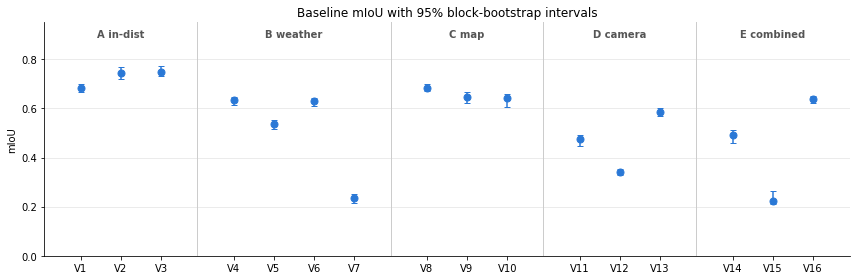

In [21]:
# Block bootstrap confidence intervals
import numpy as np
import torch
from pathlib import Path
from bootstrap import DOMAINS, run_bootstrap, print_summary, plot_intervals
from model import LightUNet
from carla_labels import NUM_CLASSES

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# The replicates are seeded, so a cache newer than the checkpoint reproduces them
# exactly; delete it to recompute.
CKPT  = Path("checkpoints/best_model.pth")
CACHE = CKPT.parent / "bootstrap_cache.npz"
if CACHE.exists() and CACHE.stat().st_mtime >= CKPT.stat().st_mtime:
    z = np.load(CACHE)
    point = {d: float(z[f"point_{d}"]) for d in DOMAINS}
    boot  = {d: z[f"boot_{d}"] for d in DOMAINS}
    print(f"Using cached bootstrap results from {CACHE} (delete it to recompute)")
else:
    model = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
    model.load_state_dict(torch.load(CKPT, map_location=DEVICE)["model_state_dict"])
    model.eval()
    point, boot = run_bootstrap(model, DEVICE)
    np.savez(CACHE, **{f"point_{d}": v for d, v in point.items()},
                    **{f"boot_{d}": v for d, v in boot.items()})

print_summary(point, boot)
plot_intervals(point, boot)

**Augmentation ablation.** Three variants retrain the same network with the baseline recipe and checkpoint selection and differ only in the training transform defined in the Dataset and Transforms section: `photo` (strong darkening), `geo` (shift-scale-rotate), and `full` (both). Mean mIoU change against the baseline per block:

| Block | `photo` | `geo` | `full` |
|---|---|---|---|
| A in-distribution | −0.009 | −0.001 | −0.002 |
| B weather and lighting | +0.049 | −0.024 | +0.047 |
| C map geometry | −0.021 | +0.008 | +0.003 |
| D camera | −0.045 | +0.091 | +0.077 |
| E combined | +0.042 | −0.038 | +0.029 |

Each arm improves its target block and costs accuracy on the other axis; `full` keeps both gains at an in-distribution cost of 0.002. Observation 6 in the analysis section reads these numbers against the predictions the transforms section registered.

In [22]:
# Baseline against augmentation variant
# Evaluates every trained variant checkpoint on all sixteen domains and compares it with the baseline.
import json
import numpy as np
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from dataset import SegmentationDataset
from model import LightUNet
from evaluation import evaluate_model
from carla_labels import NUM_CLASSES

if torch.cuda.is_available():
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    DEVICE = torch.device(f"cuda:{int(np.argmax(free))}")
else:
    DEVICE = torch.device("cpu")
print("Evaluating on", DEVICE)
CHECKPOINTS = {"baseline": Path("checkpoints/best_model.pth")}
CHECKPOINTS.update({v: Path(f"checkpoints_{v}/best_model.pth")
                    for v in ("photo", "geo", "full")})
DOMAINS = {f"V{i}": Path(f"data/extracted/V{i}") for i in range(1, 17)}
BLOCKS = {"A in-dist": ["V1", "V2", "V3"],
          "B weather": ["V4", "V5", "V6", "V7"],
          "C map":     ["V8", "V9", "V10"],
          "D camera":  ["V11", "V12", "V13"],
          "E combined": ["V14", "V15", "V16"]}

results = {}
for name, ckpt in CHECKPOINTS.items():
    if not ckpt.exists():
        print(f"SKIP {name}: {ckpt} not found (train it first)")
        continue
    # persisted next to the checkpoint so the numbers survive kernel restarts;
    # reused while newer than the checkpoint -- delete it to re-evaluate
    cache = ckpt.parent / "eval_16_domains.json"
    if cache.exists() and cache.stat().st_mtime >= ckpt.stat().st_mtime:
        cached = json.loads(cache.read_text())
        if all(dom in cached for dom in DOMAINS):
            results[name] = cached
            print(f"{name}: using cached results from {cache}")
            continue
    model = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)["model_state_dict"])
    model.eval()
    res = {}
    for dom, path in DOMAINS.items():
        ds = SegmentationDataset(path, split="val")
        loader = DataLoader(ds, batch_size=8, shuffle=False,
                            num_workers=0, pin_memory=False)
        res[dom] = evaluate_model(model, loader, num_classes=NUM_CLASSES, device=DEVICE)
    results[name] = res
    cache.write_text(json.dumps(
        {d: {"mIoU": r["mIoU"], "per_class_iou": r["per_class_iou"]}
         for d, r in res.items()}, indent=2))

assert "baseline" in results, "baseline checkpoint missing"
variants = [n for n in results if n != "baseline"]

hdr = f"{'dom':<5s}{'baseline':>10s}" + "".join(f"{v:>10s}{'d':>8s}" for v in variants)
print(hdr)
print("-" * len(hdr))
for dom in DOMAINS:
    base = results["baseline"][dom]["mIoU"]
    line = f"{dom:<5s}{base:>10.4f}"
    for v in variants:
        m = results[v][dom]["mIoU"]
        line += f"{m:>10.4f}{m - base:>+8.3f}"
    print(line)

print("\nMean mIoU delta vs baseline per block:")
for bname, doms in BLOCKS.items():
    line = f"  {bname:<11s}"
    for v in variants:
        d = np.mean([results[v][x]["mIoU"] - results["baseline"][x]["mIoU"] for x in doms])
        line += f"  {v}: {d:+.3f}"
    print(line)

print("\nMarker classes (mechanism checks from the Analysis section):")
for dom, cls in [("V7", "sky"), ("V15", "sky"), ("V12", "building"), ("V11", "vehicle")]:
    line = f"  {dom:<4s}{cls:<9s} baseline: {results['baseline'][dom]['per_class_iou'][cls]:.3f}"
    for v in variants:
        line += f"   {v}: {results[v][dom]['per_class_iou'][cls]:.3f}"
    print(line)


Evaluating on cuda:0
baseline: using cached results from checkpoints/eval_16_domains.json
photo: using cached results from checkpoints_photo/eval_16_domains.json
geo: using cached results from checkpoints_geo/eval_16_domains.json
full: using cached results from checkpoints_full/eval_16_domains.json
dom    baseline     photo       d       geo       d      full       d
---------------------------------------------------------------------
V1       0.6832    0.6701  -0.013    0.6886  +0.005    0.6729  -0.010
V2       0.7433    0.7447  +0.001    0.7444  +0.001    0.7526  +0.009
V3       0.7491    0.7325  -0.017    0.7398  -0.009    0.7434  -0.006
V4       0.6347    0.6330  -0.002    0.6336  -0.001    0.6314  -0.003
V5       0.5381    0.5691  +0.031    0.5303  -0.008    0.5926  +0.054
V6       0.6281    0.6414  +0.013    0.6194  -0.009    0.6433  +0.015
V7       0.2333    0.3851  +0.152    0.1564  -0.077    0.3564  +0.123
V8       0.6832    0.6780  -0.005    0.6960  +0.013    0.6907  +0.007


The figure below compares the absolute mIoU of all four models on every domain, grouped by block; the delta table above carries the exact values. Changes below about 0.02 sit inside the measured sampling noise.


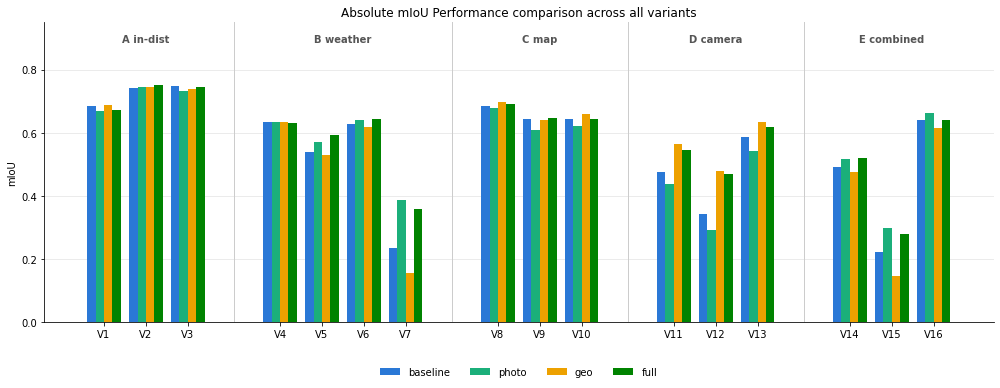

In [23]:
# Grouped bar comparison per variant 
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RUNS = {"baseline": "checkpoints", "photo": "checkpoints_photo",
        "geo": "checkpoints_geo", "full": "checkpoints_full"}
R = {n: json.loads((Path(d) / "eval_16_domains.json").read_text())
     for n, d in RUNS.items() if (Path(d) / "eval_16_domains.json").exists()}
assert "baseline" in R, "run the comparison cell first"

doms = [f"V{i}" for i in range(1, 17)]
blocks = [("A in-dist", 0, 3), ("B weather", 3, 7), ("C map", 7, 10),
          ("D camera", 10, 13), ("E combined", 13, 16)]

# Set up the baseline X positions with gaps between domain blocks
x = np.arange(len(doms), dtype=float)
for _, s, e in blocks[1:]:
    x[s:] += 1.2  

COLORS = {
    "baseline": "#2a78d6", 
    "photo": "#1baf7a", 
    "geo": "#eda100", 
    "full": "#008300"
}

width = 0.20
offsets = {
    "baseline": -1.5 * width,
    "photo":    -0.5 * width,
    "geo":       0.5 * width,
    "full":      1.5 * width
}

fig, ax = plt.subplots(figsize=(14, 5.5))

# Plot the absolute mIoU for each run configuration side-by-side
for name in ("baseline", "photo", "geo", "full"):
    if name not in R:
        continue
    scores = np.array([R[name][d]["mIoU"] for d in doms])
    ax.bar(x + offsets[name], scores, width=width, color=COLORS[name],
           edgecolor="none", label=name, zorder=3)

# Add domain boundary section markers and vertical lines
for label, s, e in blocks:
    ax.text((x[s] + x[e - 1]) / 2, 0.88, label, ha="center", va="bottom",
             fontsize=10, color="#555555", fontweight='bold')
    if s > 0:
        ax.axvline((x[s] + x[s - 1]) / 2, color="#cccccc", lw=1, zorder=1)

# Polish axes aesthetics
ax.set_ylabel("mIoU")
ax.set_ylim(0, 0.95)
ax.set_title("Absolute mIoU Performance comparison across all variants")
ax.set_xticks(x)
ax.set_xticklabels(doms)

ax.yaxis.grid(True, color="#e6e6e6", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

# Add standard legend underneath the graph
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)

plt.tight_layout()
plt.show()

## 2. Qualitative Evaluation

The figure below compares RGB input, ground truth, and prediction on one mid-sequence frame each from V1 (top row), V5 HardRainNoon (middle), and V7 ClearNight (bottom).

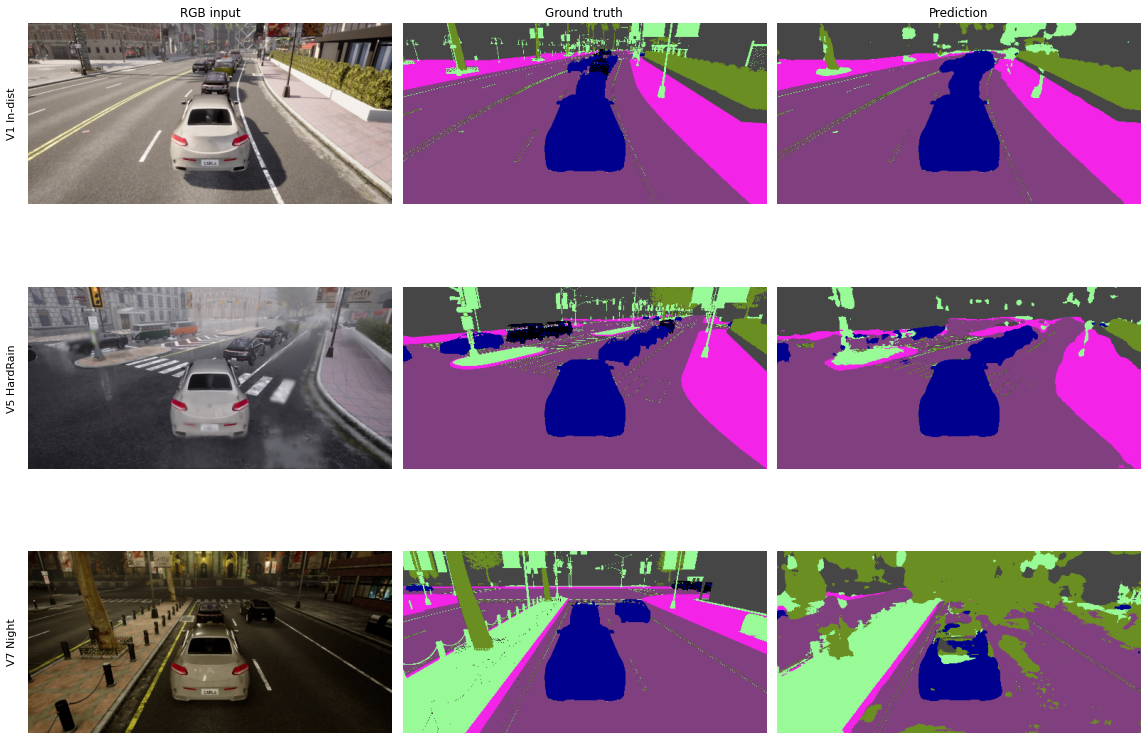

In [24]:
# Qualitative comparison: V1 vs V5 (rain) vs V7 (night)
# One mid-sequence frame per domain: RGB input, ground truth, prediction.
import torch
import matplotlib.pyplot as plt
from pathlib import Path

from dataset import SegmentationDataset
from model import LightUNet
from carla_labels import NUM_CLASSES, label_to_color_image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load("checkpoints/best_model.pth",
                                 map_location=DEVICE)["model_state_dict"])
model.eval()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

qual_domains = {
    "V1 In-dist":  Path("data/extracted/V1"),
    "V5 HardRain": Path("data/extracted/V5"),
    "V7 Night":    Path("data/extracted/V7"),
}

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for col, title in enumerate(["RGB input", "Ground truth", "Prediction"]):
    axes[0, col].set_title(title, fontsize=12)

with torch.no_grad():
    for row, (name, path) in enumerate(qual_domains.items()):
        ds  = SegmentationDataset(path, split="val")
        idx = len(ds) // 2
        img_t, lbl_t = ds[idx]
        pred = model(img_t.unsqueeze(0).to(DEVICE)).argmax(1).squeeze().cpu().numpy()
        rgb  = (img_t * std + mean).permute(1, 2, 0).numpy().clip(0, 1)
        axes[row, 0].imshow(rgb);                                  axes[row, 0].axis("off")
        axes[row, 0].text(-0.03, 0.5, name, transform=axes[row, 0].transAxes,
                          rotation=90, va="center", ha="right", fontsize=11)
        axes[row, 1].imshow(label_to_color_image(lbl_t.numpy()));  axes[row, 1].axis("off")
        axes[row, 2].imshow(label_to_color_image(pred));           axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

**V1, in-distribution.** The prediction reproduces the scene layout: road, both sidewalks, the ego vehicle, the hedge on the right, and the building walls match the ground truth. Errors concentrate in thin structures. Poles and overhead wires, which the schema maps to "other", come out as coarse blobs or vanish, and the queue of cars further up the street loses its separation. Those blobs match the 0.49 "other" IoU on this domain.

**V5, hard rain.** The scene keeps its geometry and loses contrast. The model finds the road, the crosswalk area, and the ego vehicle. The queued cars on the left fragment into patches of vehicle, sidewalk, and building, a pale-green "other" patch replaces part of the left sidewalk, and the hazy background merges into one building mass. Sky IoU drops to 0.25 here.

**V7, night.** The model keeps the headlight-lit road surface and most of the ego vehicle. It floods the lower left of the frame with road where the ground truth has sidewalk, keeps only a displaced wedge of that sidewalk, paints the dark upper half as vegetation and building patches, and drops the bollards along the kerb. The two cars ahead shrink to fragments. Sidewalk IoU sits at 0.03 on this domain and sky at 0.00; the frame shows the same failure as one olive-and-grey smear where the ground truth separates trees, facades, and poles.

## 3. Analysis and Discussion

We explain the mIoU ranking in six observations, drawing on the per-class heatmap in the Experiments section, the scene-composition figure, the augmentation comparison, and the confusion matrices below.

The cell below computes each domain's ground-truth class shares and the share of each class's pixels that lie on a class boundary, prints the values, and draws the shares as stacked bars in the report's segmentation palette. Observations 1 and 4 read them.


dom         road   sidewalk   building vegetation    vehicle pedestrian        sky      other   void
----------------------------------------------------------------------------------------------------
V1       45.346%    11.875%    16.261%     6.374%    14.184%     0.013%     0.454%     5.494%  1.61%
V2       32.328%    23.323%    12.141%     8.589%     9.623%     0.025%     1.993%    11.979%  0.94%
V3       42.025%    16.816%    15.949%     5.697%    12.645%     0.036%     0.740%     6.093%  2.41%
V4       49.476%    12.026%    15.878%     3.598%    12.011%     0.016%     0.490%     6.505%  2.61%
V5       44.713%    12.747%    16.370%     5.570%    14.021%     0.022%     0.560%     5.998%  3.81%
V6       46.695%     9.952%    15.699%     4.603%    14.453%     0.015%     0.402%     8.182%  2.86%
V7       47.332%    11.375%    16.033%     4.573%    13.082%     0.020%     0.461%     7.125%  2.91%
V8       32.405%    24.261%    21.161%     3.858%    10.062%     0.036%     0.873%     7.34

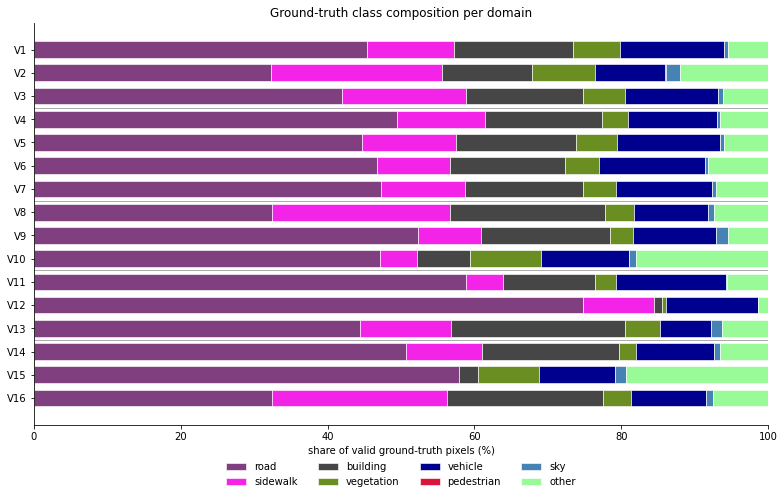

In [25]:
import numpy as np
import cv2
from pathlib import Path
from carla_labels import REDUCED_CLASSES

domains = {f"V{i}": Path(f"data/extracted/V{i}") for i in range(1, 17)}
counts = {}
for name, root in domains.items():
    c = np.zeros(256, dtype=np.int64)
    for p in sorted((root / "labels").glob("*.png")):
        c += np.bincount(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE).ravel(),
                         minlength=256)
    counts[name] = c

header = f"{'dom':<5s}" + "".join(f"{REDUCED_CLASSES[i]:>11s}" for i in range(8)) + f"{'void':>7s}"
print(header)
print("-" * len(header))
for name, c in counts.items():
    valid = c[:8].sum()
    row = "".join(f"{c[i] / valid * 100:>10.3f}%" for i in range(8))
    print(f"{name:<5s}" + row + f"{c[255] / (valid + c[255]) * 100:>6.2f}%")

kernel = np.ones((3, 3), np.uint8)
print(f"\n{'dom':<5s}{'class':<8s}{'share':>8s}{'edge-frac':>10s}")
for name in ["V1", "V2", "V3", "V8"]:
    for cls in (6, 7):  # sky, other
        tot = ero = 0
        for p in sorted((domains[name] / "labels").glob("*.png")):
            m = (cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) == cls).astype(np.uint8)
            tot += int(m.sum())
            ero += int(cv2.erode(m, kernel).sum())
        share = tot / counts[name][:8].sum() * 100
        print(f"{name:<5s}{REDUCED_CLASSES[cls]:<8s}{share:>7.2f}%{1 - ero / tot:>10.3f}")

import matplotlib.pyplot as plt
from carla_labels import CLASS_COLORS

names = list(domains)
shares = np.array([counts[n][:8] / counts[n][:8].sum() * 100 for n in names])
y = np.arange(len(names))[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
left = np.zeros(len(names))
for cls in range(8):
    ax.barh(y, shares[:, cls], left=left, height=0.72,
            color=np.array(CLASS_COLORS[cls]) / 255.0,
            edgecolor="white", linewidth=0.6, label=REDUCED_CLASSES[cls])
    left += shares[:, cls]
for start in (3, 7, 10, 13):
    ax.axhline(y[start] + 0.5, color="#999999", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(names)
ax.set_xlim(0, 100)
ax.set_xlabel("share of valid ground-truth pixels (%)")
ax.set_title("Ground-truth class composition per domain")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=4, frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


**1. Scene statistics set the cross-map scores.** V1 (Town10HD, in-distribution) scores 0.6832, identical to four decimals with the unseen Town02 (V8) and about 0.06 below the other two training towns. The per-class rows locate the gap in the two rare classes: sky 0.71 on Town10HD against 0.88 to 0.89 elsewhere in Block A, "other" 0.49 against 0.62 to 0.75. The composition tables above explain both. The chase camera, pitched 20° down, keeps sky under 2% of the valid pixels in every town; Town10HD sits lowest at 0.45%, and sky IoU follows share across the training towns: 0.71 at a 0.45% share, 0.88 at 0.74%, 0.89 at 2.0%. A scarce class offers a small target, so the same absolute error costs it more IoU. For "other", Town10HD carries less street furniture than Town01 (5.5% of pixels against 12.0%) but in the most fragmented form: 39% of its "other" pixels lie within one pixel of a class boundary, against 19% on Town01, thin poles and signs against long fences. Within the training towns, "other" IoU rises with share and contiguity: 0.49, then 0.62, then 0.75. Town02 (V8) supplies the other half of the explanation: its composition sits close to Town01's, sidewalk-heavy with mid-range "other" contiguity, yet its "other" IoU (0.46) falls below every training town. The unseen-map penalty concentrates in the rare-furniture tail while road, vehicle, and building transfer, so an easy composition and a novelty penalty cancel, and V8 matches V1. Cross-map mIoU therefore reads scene statistics as much as robustness, and only within-map deltas isolate a shift.

**2. The V16 inversion dissolves under map-matched references.** The combined V16 (Town02 + Sunset, 0.640) outscores the single-shift V6 (Town10HD + Sunset, 0.628), yet against their own baselines sunset costs a similar −0.055 on Town10HD and −0.043 on Town02; the inversion is the cross-map confound of observation 1.

mIoU states how much a shift costs; a confusion matrix states what the model mistakes for what. The cell below computes row-normalised confusion (each ground-truth class's pixels, split by predicted class) for the two most selective failures, V7 night and V12 pitch, with the baseline checkpoint. Observations 3 and 4 rest on these numbers.


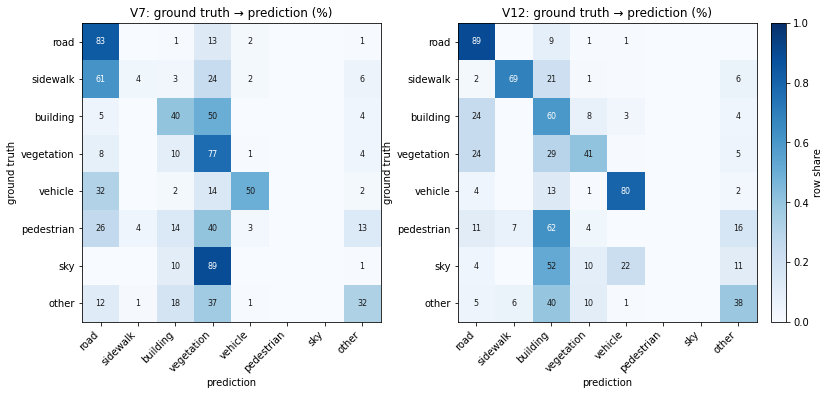

In [26]:
# confusion matrices for V7 (night) and V12 (pitch)
# Where do the lost pixels go? 
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from dataset import SegmentationDataset
from model import LightUNet
from carla_labels import NUM_CLASSES, REDUCED_CLASSES

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load("checkpoints/best_model.pth",
                                 map_location=DEVICE)["model_state_dict"])
model.eval()

CLS = [REDUCED_CLASSES[i] for i in range(NUM_CLASSES)]
mats = {}
with torch.no_grad():
    for dom in ("V7", "V12"):
        ds = SegmentationDataset(f"data/extracted/{dom}", split="val")
        loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=0)
        conf = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
        for img, lbl in loader:
            pred = model(img.to(DEVICE)).argmax(1).cpu().numpy().ravel()
            gt = lbl.numpy().ravel()
            m = gt != 255
            conf += np.bincount(gt[m] * NUM_CLASSES + pred[m],
                                minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
        mats[dom] = conf

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (dom, conf) in zip(axes, mats.items()):
    rows = conf / conf.sum(1, keepdims=True).clip(min=1)
    im = ax.imshow(rows, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLS, rotation=45, ha="right")
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels(CLS)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            v = rows[i, j]
            if v >= 0.005:
                ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center",
                        fontsize=8, color="white" if v > 0.55 else "#1a1a1a")
    ax.set_title(f"{dom}: ground truth \u2192 prediction (%)")
    ax.set_ylabel("ground truth")
    ax.set_xlabel("prediction")
fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, label="row share")
plt.show()


The next cell adds a causal check for the night analysis: it re-evaluates the frozen baseline on V1 with every frame darkened by a constant factor, from 1.0 down to 0.15, with no retraining. If mIoU at night-level brightness lands near the real V7 score, darkness alone reproduces the collapse.

Evaluating: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 81/81 [00:21<00:00,  3.76it/s]


brightness x1.0    mIoU = 0.6832
brightness x0.7    mIoU = 0.6438
brightness x0.5    mIoU = 0.5573
brightness x0.35   mIoU = 0.4380
brightness x0.25   mIoU = 0.3175
brightness x0.2    mIoU = 0.2501
brightness x0.15   mIoU = 0.1768


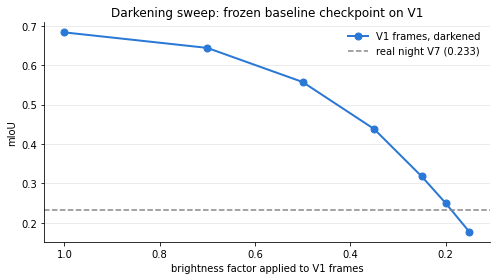

In [27]:
# Does darkness alone reproduce the night collapse? 
import json
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

from dataset import SegmentationDataset, MEAN, STD
from model import LightUNet
from evaluation import evaluate_model
from carla_labels import NUM_CLASSES

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load("checkpoints/best_model.pth",
                                 map_location=DEVICE)["model_state_dict"])
model.eval()

mean_t = torch.tensor(MEAN).view(1, 3, 1, 1)
std_t  = torch.tensor(STD).view(1, 3, 1, 1)

class DarkenedLoader:
    def __init__(self, loader, factor):
        self.loader = loader
        self.factor = factor
        self.shift  = (factor - 1.0) * mean_t / std_t
    def __iter__(self):
        for images, labels in self.loader:
            yield images * self.factor + self.shift, labels
    def __len__(self):
        return len(self.loader)

FACTORS    = [1.0, 0.7, 0.5, 0.35, 0.25, 0.20, 0.15]
NIGHT_MIOU = 0.2333

# Reused while newer than the checkpoint and for the same factors; delete to recompute.
CKPT  = Path("checkpoints/best_model.pth")
CACHE = CKPT.parent / "darkening_sweep.json"
sweep = {}
if CACHE.exists() and CACHE.stat().st_mtime >= CKPT.stat().st_mtime:
    sweep = {f: m for f, m in json.loads(CACHE.read_text())}
    if list(sweep) == FACTORS:
        print(f"Using cached sweep from {CACHE} (delete it to recompute)")
    else:
        sweep = {}

if not sweep:
    ds     = SegmentationDataset(Path("data/extracted/V1"), split="val")
    loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=0)
    for f in FACTORS:
        res = evaluate_model(model, DarkenedLoader(loader, f),
                             num_classes=NUM_CLASSES, device=DEVICE)
        sweep[f] = res["mIoU"]
    CACHE.write_text(json.dumps([[f, sweep[f]] for f in FACTORS]))

for f in FACTORS:
    print(f"brightness x{f:<5}  mIoU = {sweep[f]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(FACTORS, [sweep[f] for f in FACTORS], "o-", lw=2, markersize=7,
        color="#2a78d6", label="V1 frames, darkened")
ax.axhline(NIGHT_MIOU, color="#888888", ls="--", lw=1.5,
           label=f"real night V7 ({NIGHT_MIOU:.3f})")
ax.invert_xaxis()   # darker to the right
ax.set_xlabel("brightness factor applied to V1 frames")
ax.set_ylabel("mIoU")
ax.set_title("Darkening sweep: frozen baseline checkpoint on V1")
ax.legend(frameon=False)
ax.yaxis.grid(True, color="#e6e6e6", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**3. Night removes cues, not accuracy uniformly.** Both night domains drive sky to 0.00: the model learned sky as a bright, low-texture region at the top of the frame, and at night it sends 89% of the sky pixels to vegetation and 10% to building, as the confusion matrices above show and the qualitative figure displays as the olive-and-grey smear. Sidewalk follows in V7: it covers 11% of that domain's pixels, yet its IoU falls to 0.03, because the road/sidewalk boundary is a low-contrast colour-and-texture edge that darkness erases; the freed pixels default to road (61% of sidewalk pixels land there), which stays comparatively high (0.65 and 0.76), anchored by its position at the bottom of the frame and by street lighting. Vegetation falls to 0.13 in V7. Night therefore wipes out the classes whose discriminative cue is brightness or fine texture and spares the ones anchored by image position. The darkening sweep above makes this attribution causal: scaling in-distribution V1 frames to 20% brightness drives the unchanged model to 0.250 mIoU and 15% to 0.177, bracketing the real night score of 0.233, so uniform darkness alone reproduces the whole collapse. This sharpens the augmentation reading in observation 6: darkness suffices to break the model, while training on darkened frames recovers real night only in part (0.385), because recognising a night scene needs appearances that darkening cannot synthesise: lit windows, headlights, the night sky.

The pair below shows the two viewpoint failures of Block D, one mid-sequence frame each. At bumper height (V11), the ego vehicle, the most constant object in the training data, shatters into fragments; under the pitched-down view (V12), the prediction stamps a grey building stripe across the top of the frame, over cars, road, and sidewalk alike.


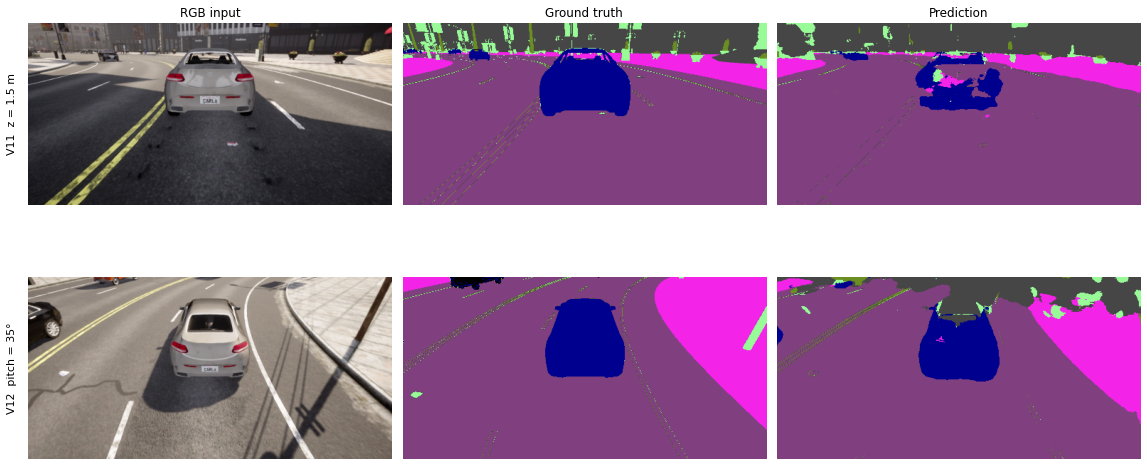

In [28]:
# Camera block failure (V11, V12) 
import numpy as np
import torch
import matplotlib.pyplot as plt
from dataset import SegmentationDataset
from model import LightUNet
from carla_labels import NUM_CLASSES, label_to_color_image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LightUNet(num_classes=NUM_CLASSES).to(DEVICE)
model.load_state_dict(torch.load("checkpoints/best_model.pth",
                                 map_location=DEVICE)["model_state_dict"])
model.eval()
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

rows = {"V11  z = 1.5 m": "data/extracted/V11",
        "V12  pitch = 35\u00b0": "data/extracted/V12"}
fig, axes = plt.subplots(2, 3, figsize=(16, 8.2))
for col, t in enumerate(["RGB input", "Ground truth", "Prediction"]):
    axes[0, col].set_title(t, fontsize=12)
with torch.no_grad():
    for r, (name, path) in enumerate(rows.items()):
        ds = SegmentationDataset(path, split="val")
        img_t, lbl_t = ds[len(ds) // 2]
        pred = model(img_t.unsqueeze(0).to(DEVICE)).argmax(1).squeeze().cpu().numpy()
        rgb = (img_t * std + mean).permute(1, 2, 0).numpy().clip(0, 1)
        axes[r, 0].imshow(rgb)
        axes[r, 1].imshow(label_to_color_image(lbl_t.numpy()))
        axes[r, 2].imshow(label_to_color_image(pred))
        for c in range(3):
            axes[r, c].axis("off")
        axes[r, 0].text(-0.03, 0.5, name, transform=axes[r, 0].transAxes,
                        rotation=90, va="center", ha="right", fontsize=11)
plt.tight_layout()
plt.show()


**4. The camera block exposes a position prior.** V12 (pitch 35°) is the most selective failure in the study: road holds 0.88 while building collapses to 0.06 and sky to 0.00. Pitching the camera down by 15° shifts the whole scene upward in the image: buildings fall from 16.3% of V1's pixels to 1.1%, sky from 0.45% to 0.002%, and road grows from 45% to 75%. The confusion matrix corrects our first reading of this failure: the model still finds 60% of the remaining building pixels and predicts sky almost nowhere. The collapse comes from false positives instead. In the shifted upper rows the model stamps building over sidewalk (22% of its pixels), vegetation (30%), and "other" (40%), the classes that occupied that band at the training pitch, and with true building down to 1.1% of the frame these false positives crush the union. The prior the model carries is an upper-band building prior, applied to whatever the new viewpoint puts there; the camera-block frames above show the resulting grey building stripe across the top rows. V11 (mount lowered to 1.5 m) shows the complementary break: object scale and the ego vehicle's framing change, and vehicle IoU halves from 0.91 to 0.47 although each car keeps its local appearance. The two failures share a cause: training on a single rigid camera couples class identity to absolute image coordinates, a capacity Islam et al. [[11]](#ref11) show convolutional networks acquire through zero-padding boundary effects. This is the practical risk when a model trained for one sensor mount is reused on a vehicle with a different one, and it explains why Block D ranks directly behind night in the cost table.

**5. The chase view inflates the vehicle class.** The ego vehicle fills a large, constant part of every frame, so the model keeps segmenting it when most other classes fail (vehicle IoU 0.45 in V7, 0.54 in V15). The vehicle column therefore overstates robustness to appearance shifts; a forward-facing camera would likely score lower.

**6. Augmentation shifts cue reliance and costs accuracy on the other axis.** The geometric arm behaves as registered: Block D gains +0.091 mIoU on average, the gains order as pitch (+0.137), then height (+0.088), then FOV (+0.048), V12 building climbs from 0.06 to 0.32, and V11 vehicle from 0.47 to 0.72. Training the position and scale priors away releases much of the camera penalty. The photometric arm confirms its block-level prediction, night mIoU rises from 0.233 to 0.385 (V7) and from 0.221 to 0.298 (V15), but its marker misses: night sky reaches at most 0.06 across all variants. Sidewalk recovers instead, from 0.03 to 0.27 in V7. Darkened noon frames teach the model to separate road from sidewalk in low light, yet they contain no night sky, so the sky failure is missing scene content rather than missing brightness range, the exact limit the transforms section states. The costs are as informative as the gains: `photo` loses 0.045 on Block D and `geo` loses about 0.075 on each night domain. This mirrors observations 3 and 4: the position prior that `geo` trains away is the same prior that held road and the scene layout together in the dark, and `photo`'s colour invariance shifts reliance toward the geometry that Block D breaks. `full` retains both gains (+0.047 on Block B, +0.077 on Block D) at a 0.002 in-distribution cost, so the two arms act nearly independently, the same near-additivity the domain shifts themselves show. For deployment, match the augmentation to the shift family you expect, or combine both arms at a 0.002 in-distribution cost.

**Known limits of the measurement.** Pedestrian IoU stays between 0.00 and 0.04 in every domain: at 0.006% of training pixels the model never learned the class (see the label-schema section). In a recording with a near-empty class (V15: no pedestrians, 252 sidewalk pixels), stray predictions alone set that class's IoU. The near-zero enters every mean either way and compresses all mIoU values by roughly one eighth; dropping the class would lift V1 from 0.683 to about 0.78 without changing any ordering or delta sign, so we keep the 8-class mean for comparability across domains. Second, every number comes from a single training run without a fixed seed and from one 10-minute recording per domain. The block bootstrap in section 1 quantifies the recording half of this limit: its 95% intervals have a median half-width of ±0.017 across domains (at most ±0.027, on V10), every shift cost Δ in the table above keeps its sign, including the smallest (V8's −0.042 and V16's −0.043), and the two contrasts we treat as ties come out as such: V9 − V10 spans [−0.026, +0.043] and wet − sunset [−0.018, +0.028], both straddling zero. The 0.02 threshold we use for conclusions therefore matches the measured sampling noise, but not the unmeasured variance of a single unseeded training run. Third, the JPEG-compressed label stream decodes with errors concentrated in a thin band along class boundaries, so fragmented classes carry noisier ground truth than contiguous ones. This confound acts on the same axis as the contiguity argument of observation 1: part of the “other” IoU spread attributed there to fragmentation is measurement noise in the labels themselves, so the contiguity reading is an upper bound on the model's own contribution.

## 4. Comparison with Related Work

Our degradation ranking matches SHIFT's [[3]](#ref3). Sun et al. find that nighttime lowers segmentation mIoU the most, below rain and fog, while overcast and cloudy conditions cost little (Table 2 in [[3]](#ref3)). We observe the same order: night (0.23 and 0.22) falls below hard rain (0.54), and wet roads and low sun hold near 0.63, against an in-distribution 0.68 to 0.75. The absolute scores differ: SHIFT trains DeepLabv3+ on millions of frames over nineteen classes, while we train a 7.3M-parameter U-Net on a few thousand frames over eight. Sun et al. argue that the ranking of degradation, rather than the absolute accuracy, transfers across datasets and to real-world BDD100K. Our experiment supports that claim from a much cheaper setup, since the same shift order emerges. Two of our results extend the weather axis. Unseen map geometry costs little (Block C, 0.64 to 0.68), so the model generalizes across road layouts better than across appearance. Camera pitch, which SHIFT lists but reports little on, ranks among our most damaging shifts (V12, 0.34) and points to a viewpoint dependence worth its own study. One limit separates our setup from SHIFT's: our model never learned the pedestrian class (see Known limits), so we report no pedestrian shift effect.

# Conclusion

We measured what controlled domain shifts cost a semantic segmentation model trained on synthetic data alone: a 7.3M-parameter LightUNet, trained on 4,697 ClearNoon frames from three towns, against sixteen CARLAB domains in five blocks that each isolate one variable, measured against map-matched references.

Night costs the most: mIoU falls from 0.68 on the training map to 0.23, and to 0.22 on an unseen highway. Camera geometry ranks second. Pitching the camera down 15° cuts mIoU to 0.34 and halving the mount height cuts it to 0.48; the per-class breakdown traces both to priors the model absorbed from a fixed training viewpoint, with class identity tied to image position and scale. Hard rain costs 0.15 mIoU, while sunset, wet roads, and three unseen towns cost 0.04 to 0.08 each. Combined map-plus-weather domains land within 0.03 of the sum of their single-shift costs. The order of these drops matches SHIFT's large-scale result [[3]](#ref3) from a training set about 500 times smaller.

A three-arm augmentation ablation ties these mechanisms down. Geometric warping recovers much of the camera penalty (pitch mIoU 0.34 to 0.48) and photometric darkening much of the night penalty (0.23 to 0.39); each arm costs accuracy on the other shift axis, and combining them keeps both gains at an in-distribution cost of 0.002.

The ROS 2 package carries the study into live operation: an inference node segments the CARLAB camera stream, and an evaluation node synchronises predictions with simulator ground truth and publishes frame-level and cumulative mIoU. In a ten-pair replay, the ROS metric counts matched an independent confusion matrix of the received predictions exactly. A completed live run accumulated 461 evaluated pairs with mIoU 0.6243. On ten captured semantic messages, the revised decoder reduced median decoding time by 3.93x without changing the decoded masks.

Three limits bound these claims. The offline domain-shift estimates come from one baseline training run without a fixed seed; the block bootstrap bounds recording noise at a median ±0.017 mIoU and confirms the sign of every shift cost, but not training variance. The chase-view camera keeps the ego vehicle in frame and flatters the vehicle class. The pedestrian class never rose above 0.04 IoU and stays outside the measured claims. Two extensions follow from the results: repeating the study with a forward-facing camera and several seeds, and testing whether the near-additivity of combined shifts survives camera-plus-weather stacks and real-world data, the sim-to-real direction SHIFT motivates.

# References

| # | Year | Authors | Title |
| --- | --- | --- | --- |
| 1<a id="ref1"></a> | 2017 | A. Dosovitskiy et al. | [CARLA: An Open Urban Driving Simulator](https://proceedings.mlr.press/v78/dosovitskiy17a.html) |
| 2<a id="ref2"></a> | 2022 | P. Testolina et al. | [SELMA: SEmantic Large-scale Multimodal Acquisitions in Variable Weather, Daytime and Viewpoints](https://arxiv.org/abs/2204.09788) |
| 3<a id="ref3"></a> | 2022 | T. Sun et al. | [SHIFT: A Synthetic Driving Dataset for Continuous Multi-Task Domain Adaptation](https://arxiv.org/abs/2206.08367) |
| 4<a id="ref4"></a> | 2015 | J. Long, E. Shelhamer, T. Darrell | [Fully Convolutional Networks for Semantic Segmentation](https://arxiv.org/abs/1411.4038) |
| 5<a id="ref5"></a> | 2018 | L.-C. Chen et al. | [Encoder-Decoder with Atrous Separable Convolution for Semantic Image Segmentation (DeepLabv3+)](https://arxiv.org/abs/1802.02611) |
| 6<a id="ref6"></a> | 2021 | E. Xie et al. | [SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers](https://arxiv.org/abs/2105.15203) |
| 7<a id="ref7"></a> | 2016 | M. Cordts et al. | [The Cityscapes Dataset for Semantic Urban Scene Understanding](https://arxiv.org/abs/1604.01685) |
| 8<a id="ref8"></a> | 2017 | V. Badrinarayanan et al. | [SegNet: A Deep Convolutional Encoder-Decoder Architecture for Image Segmentation](https://ieeexplore.ieee.org/document/7803544) |
| 9<a id="ref9"></a> | 2016 | A. Paszke et al. | [ENet: A Deep Neural Network Architecture for Real-Time Semantic Segmentation](https://arxiv.org/abs/1606.02147) |
| 10<a id="ref10"></a> | 2015 | O. Ronneberger, P. Fischer, T. Brox | [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597) |
| 11<a id="ref11"></a> | 2020 | M. A. Islam, S. Jia, N. D. B. Bruce | [How Much Position Information Do Convolutional Neural Networks Encode?](https://arxiv.org/abs/2001.08248) |
| 12<a id="ref12"></a> | 2026 | ika, RWTH Aachen University | [CARLAB simulation platform](https://carlab.ika.rwth-aachen.de/) |
| 13<a id="ref13"></a> | 2016 | G. Ros et al. | [The SYNTHIA Dataset: A Large Collection of Synthetic Images for Semantic Segmentation of Urban Scenes](https://openaccess.thecvf.com/content_cvpr_2016/html/Ros_The_SYNTHIA_Dataset_CVPR_2016_paper.html) |
| 14<a id="ref14"></a> | 2016 | S. R. Richter et al. | [Playing for Data: Ground Truth from Computer Games](https://arxiv.org/abs/1608.02192) |
| 15<a id="ref15"></a> | 2021 | C. Sakaridis, D. Dai, L. Van Gool | [ACDC: The Adverse Conditions Dataset with Correspondences for Semantic Driving Scene Understanding](https://arxiv.org/abs/2104.13395) |
| 16<a id="ref16"></a> | 1989 | H. R. Künsch | [The Jackknife and the Bootstrap for General Stationary Observations](https://projecteuclid.org/journals/annals-of-statistics/volume-17/issue-3/The-jackknife-and-the-bootstrap-for-general-stationary-observations/10.1214/aos/1176347265.full) |

**Code and asset attribution.** We wrote all pipeline, training, evaluation, and ROS 2 code in this repository ourselves. The implementation builds on the open-source libraries installed at the top of this notebook (NumPy, OpenCV, PyTorch, torchvision, Albumentations, Matplotlib, mcap-ros2-support) and on the ROS 2 packages `rclpy`, `cv_bridge`, and `message_filters`; we use them through their public APIs and copied no source code from them.